# ExplainPhish: Word Phishing Detection
## Exploratory Data Analysis & Machine Learning Benchmark
**Role**: Senior Lead Data Scientist & Security Machine Learning Specialist  
**Dataset**: `Word_All_features.csv` (20,000 instances, OpenXML structural & macro features, 1 target label)

---

### Objectives
1. **Load and clean** dataset (impute missing OpenXML schema tags with 0 indicating tag absence).
2. **Progressive Feature Selection**: 5-feature baseline subset vs. complete 10-feature pool.
3. **Data Quality & Missing Values Audit**: Audit structural OpenXML properties and macro indicators.
4. **Target Distribution & Feature Deep Dive**: Distributions, skewness, Mann-Whitney U tests, and cybersecurity threat context for all 10 features.
5. **Linearity vs. Non-Linearity**: Mutual Information vs. Pearson $r$, Binned Scatter Plots with linear vs. polynomial curve fits, and 2D decision boundary scatter plots.
6. **Preprocessing & Artifact Export**: Stratified 80/20 train/test split, log1p variance stabilization, and standardized CSV dataset exports.
7. **Model Comparison**: Benchmark Neural Network (MLP), Random Forest, Decision Tree, XGBoost, and LightGBM with ROC curves and confusion matrices.
8. **PCA Experiment**: Scree plot, cumulative variance curve, and model performance comparison with vs. without PCA.


## 1. Setup & Library Imports
We configure scientific Python libraries and visualization parameters.


In [1]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Environment configured successfully!")


Environment configured successfully!


## 2. Loading the Data
### 2.1 Data Overview & Imputation
We load `Word_All_features.csv`, fill missing OpenXML tags with 0 (indicating absence of the structure), and select the top 10 discriminative features matching production models.


In [2]:
possible_paths = [
    Path("data/word/Word_All_features.csv"),
    Path("../data/word/Word_All_features.csv"),
    Path("trainingModel/data/word/Word_All_features.csv"),
    Path(r"d:/codingProject/ExplainPhish/trainingModel/data/word/Word_All_features.csv")
]

data_path = next((p for p in possible_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find Word_All_features.csv")

print(f"Loading data from: {data_path.resolve()}")
raw_df = pd.read_csv(data_path)

# Impute missing OpenXML path features with 0 (tag absence)
raw_df = raw_df.fillna(0)

# Top 10 Core Features matching production ExplainPhish Word model schema
all_features = [
    "struct_pos",
    "struct_typeface",
    "path_a-hlink",
    "path_a-accent3",
    "struct_script",
    "struct_ang",
    "path_/a-effectLst",
    "path_a-alpha",
    "path_/a-accent6",
    "struct_name"
]

target_col = 'label'
id_col = 'file_name'

df = raw_df[[target_col] + [c for c in all_features if c in raw_df.columns]].copy()
if id_col not in df.columns:
    df.insert(0, id_col, [f"sample_{i+1:05d}.docx" for i in range(len(df))])

print(f"Word dataset shape: {df.shape[0]:,} rows | {df.shape[1]} columns")
df.head(5)


Loading data from: D:\codingProject\ExplainPhish\trainingModel\data\word\Word_All_features.csv
Word dataset shape: 20,000 rows | 12 columns


,file_name,label,struct_pos,struct_typeface,path_a-hlink,path_a-accent3,struct_script,struct_ang,path_/a-effectLst,path_a-alpha,path_/a-accent6,struct_name
0,sample_00001.docx,1,0,0,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000
1,sample_00002.docx,0,10,66,0.0000,0.0000,60,0.0000,0.0000,0.0000,0.0000,0.0000
2,sample_00003.docx,0,0,66,0.0000,0.0000,60,0.0000,0.0000,0.0000,0.0000,0.0000
3,sample_00004.docx,0,10,66,0.0000,0.0000,60,0.0000,0.0000,0.0000,0.0000,0.0000
4,sample_00005.docx,1,0,0,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   file_name          20000 non-null  str    
 1   label              20000 non-null  int64  
 2   struct_pos         20000 non-null  int64  
 3   struct_typeface    20000 non-null  int64  
 4   path_a-hlink       20000 non-null  float64
 5   path_a-accent3     20000 non-null  float64
 6   struct_script      20000 non-null  int64  
 7   struct_ang         20000 non-null  float64
 8   path_/a-effectLst  20000 non-null  float64
 9   path_a-alpha       20000 non-null  float64
 10  path_/a-accent6    20000 non-null  float64
 11  struct_name        20000 non-null  float64
dtypes: float64(7), int64(4), str(1)
memory usage: 1.8 MB


### 2.2 Selecting Features

> **Data Science Principle:**  
> It is often difficult to perform data analysis and preprocessing on all features simultaneously from the beginning. Instead, an established best practice is to **start with a small, high-signal subset of features** to establish a baseline, and then **iteratively add features one by one**.

Here, we define:
- Target column: `label` (0 = Benign, 1 = Malicious / Phishing).
- Identifier column: `file_name`.
- Full feature pool (10 features).
- Initial Core Baseline Subset (5 features):
  1. `struct_pos` (Positioning metadata & hidden frame layout)
  2. `struct_typeface` (Typography / font table diversity)
  3. `path_a-hlink` (Hyperlink relation targets)
  4. `struct_script` (Script language definitions)
  5. `struct_ang` (Shape angle/rotation in floating lure overlays)


In [4]:
use_features = [
    "struct_pos",
    "struct_typeface",
    "path_a-hlink",
    "struct_script",
    "struct_ang"
]

print(f"Total features available : {len(all_features)}")
print(f"Initial selected features: {len(use_features)} -> {use_features}")
df[[id_col] + use_features + [target_col]].head(5)


Total features available : 10
Initial selected features: 5 -> ['struct_pos', 'struct_typeface', 'path_a-hlink', 'struct_script', 'struct_ang']


,file_name,struct_pos,struct_typeface,path_a-hlink,struct_script,struct_ang,label
0,sample_00001.docx,0,0,0.0000,0,0.0000,1
1,sample_00002.docx,10,66,0.0000,60,0.0000,0
2,sample_00003.docx,0,66,0.0000,60,0.0000,0
3,sample_00004.docx,10,66,0.0000,60,0.0000,0
4,sample_00005.docx,0,0,0.0000,0,0.0000,1


## 3. Visualizing and Understanding the Data
We audit missing values, class balance, and parametric vs. non-parametric feature characteristics.


### 3.1 Checking Missing Values
We verify data completeness after zero-absence imputation.


In [5]:
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Feature': df.columns,
    'Missing Count': missing_counts.values,
    'Missing (%)': missing_percent.values
}).sort_values(by='Missing Count', ascending=False)

print("Missing values audit (Clean Data):")
print(missing_df.to_string(index=False))

# Check structural zeros
zero_summary = pd.DataFrame({
    'Feature': all_features,
    'Zero Count': (df[all_features] == 0).sum().values,
    'Zero (%)': ((df[all_features] == 0).sum() / len(df) * 100).round(2).values
}).sort_values(by='Zero (%)', ascending=False)

print("\nFrequency of Exact Zeros (Structural Inactivity):")
zero_summary


Missing values audit (Clean Data):
          Feature  Missing Count  Missing (%)
        file_name              0       0.0000
            label              0       0.0000
       struct_pos              0       0.0000
  struct_typeface              0       0.0000
     path_a-hlink              0       0.0000
   path_a-accent3              0       0.0000
    struct_script              0       0.0000
       struct_ang              0       0.0000
path_/a-effectLst              0       0.0000
     path_a-alpha              0       0.0000
  path_/a-accent6              0       0.0000
      struct_name              0       0.0000

Frequency of Exact Zeros (Structural Inactivity):


,Feature,Zero Count,Zero (%)
3,path_a-accent3,16420,82.1000
2,path_a-hlink,16420,82.1000
8,path_/a-accent6,16420,82.1000
7,path_a-alpha,16420,82.1000
5,struct_ang,16420,82.1000
6,path_/a-effectLst,16420,82.1000
9,struct_name,16420,82.1000
0,struct_pos,6505,32.5200
4,struct_script,6429,32.1500
1,struct_typeface,6428,32.1400


**Findings on Missing Values**:<br>
- **Zero Missing Entries**: 0 NaN values across all 20,000 clean records.
- **Structural Inactivity**: `path_a-hlink == 0` represents documents with zero hyperlinks; `struct_ang == 0` represents documents without rotated shape banners.


### 3.2 Visualization and Analysis of Each Feature
We evaluate the target variable and all 10 Word OpenXML features.


#### 3.2.1 Target Column (`label`)

C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\2792479878.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Benign (0)', 'Malicious (1)'])


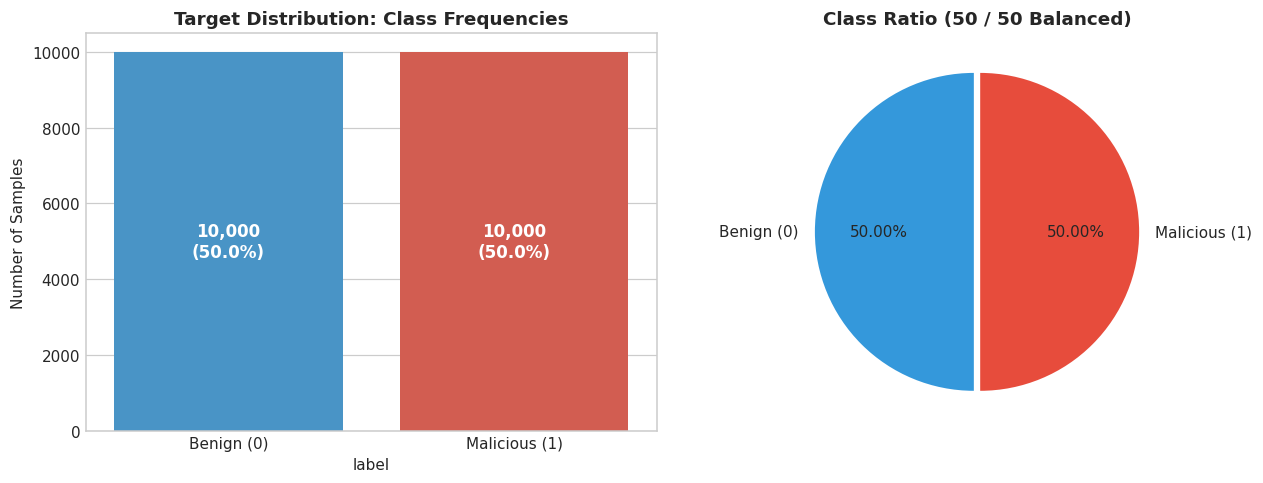

Class counts:
label
1    10000
0    10000
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

palette = {0: '#3498db', 1: '#e74c3c'}
sns.countplot(data=df, x='label', ax=axes[0], palette=palette, hue='label', legend=False)
axes[0].set_title('Target Distribution: Class Frequencies', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[0].set_ylabel('Number of Samples')

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

counts = df['label'].value_counts()
axes[1].pie(counts, labels=['Benign (0)', 'Malicious (1)'], autopct='%1.2f%%',
            startangle=90, colors=['#3498db', '#e74c3c'], explode=(0.02, 0.02))
axes[1].set_title('Class Ratio (50 / 50 Balanced)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("Class counts:")
print(df['label'].value_counts())


**Findings on Target Variable**:<br>
- Exactly **10,000 Benign (50.0%)** and **10,000 Malicious (50.0%)** samples.
- Perfect class balance eliminates majority class bias without synthetic resampling.


#### 3.2.2 Statistical Distribution & Skewness Overview

In [7]:
summary_records = []

for feat in all_features:
    s = df[feat]
    legit = df[df['label'] == 0][feat]
    phish = df[df['label'] == 1][feat]
    
    stat, p_val = stats.mannwhitneyu(phish, legit, alternative='two-sided')
    spearman_rho, _ = stats.spearmanr(df[feat], df['label'])
    pearson_r, _ = stats.pearsonr(df[feat], df['label'])
    
    summary_records.append({
        'Feature': feat,
        'Mean': s.mean(),
        'Std': s.std(),
        'Median': s.median(),
        'Skewness': s.skew(),
        'Benign Med': legit.median(),
        'Malicious Med': phish.median(),
        'MW-U p-val': p_val,
        'Spearman ρ': spearman_rho,
        'Pearson r': pearson_r
    })

stat_df = pd.DataFrame(summary_records).sort_values(by='Spearman ρ', key=abs, ascending=False).reset_index(drop=True)
stat_df


,Feature,Mean,Std,Median,Skewness,Benign Med,Malicious Med,MW-U p-val,Spearman ρ,Pearson r
0,struct_pos,6.5677,4.5772,9.0000,-0.7225,10.0000,0.0000,0.0000,-0.9162,-0.7309
1,path_a-hlink,0.1790,0.3834,0.0000,1.6748,0.0000,0.0000,0.0000,0.4669,0.4669
2,path_/a-accent6,0.1790,0.3834,0.0000,1.6748,0.0000,0.0000,0.0000,0.4669,0.4669
3,path_a-accent3,0.1790,0.3834,0.0000,1.6748,0.0000,0.0000,0.0000,0.4669,0.4669
4,path_a-alpha,0.1791,0.3838,0.0000,1.6872,0.0000,0.0000,0.0000,0.4669,0.4666
5,struct_ang,0.5370,1.1500,0.0000,1.6749,0.0000,0.0000,0.0000,0.4669,0.4669
6,path_/a-effectLst,0.1791,0.3838,0.0000,1.6872,0.0000,0.0000,0.0000,0.4669,0.4666
7,struct_name,0.8942,1.9154,0.0000,1.6755,0.0000,0.0000,0.0000,0.4669,0.4669
8,struct_typeface,49.2899,35.6996,66.0000,-0.4095,66.0000,0.0000,0.0000,-0.3754,-0.4767
9,struct_script,45.2153,33.0498,60.0000,-0.3473,60.0000,0.0000,0.0000,-0.3754,-0.4566


#### 3.2.3 `struct_pos`
**Description & Threat Context**:  
Structural positioning index of OpenXML elements. Identifies custom coordinate offsets used in floating lure graphics.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\1276445350.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


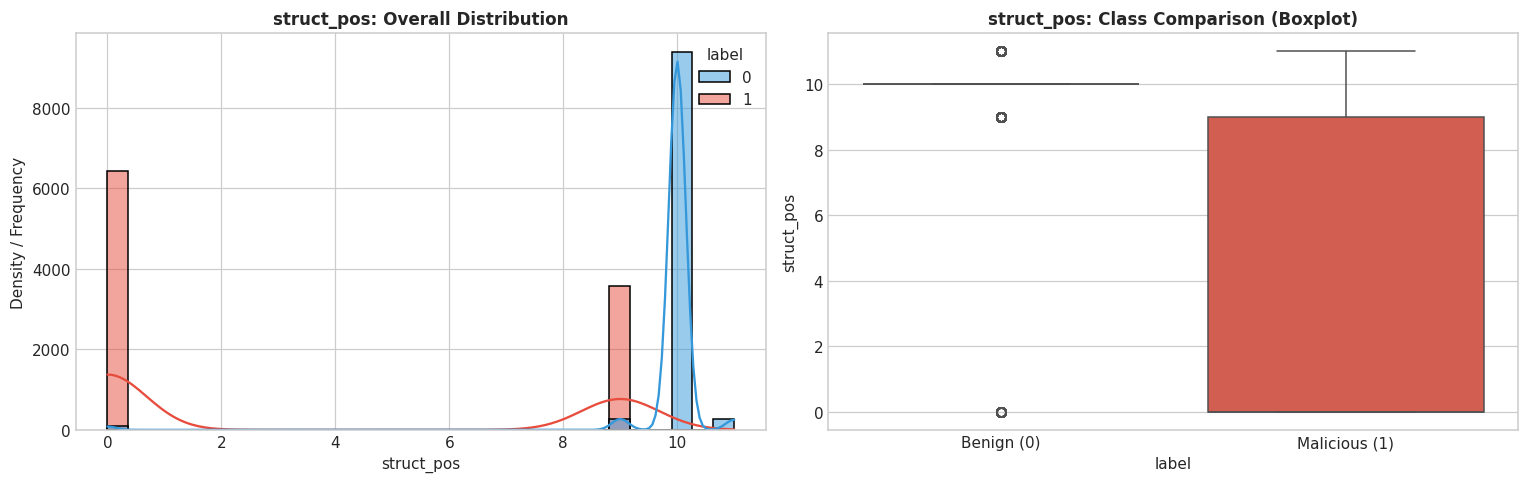

[struct_pos] Statistics:
  All Samples -> Mean: 6.5677, Median: 9.0000, Skewness: -0.72
  Benign      -> Mean: 9.9132, Median: 10.0000
  Malicious   -> Mean: 3.2222, Median: 0.0000
  Mann-Whitney U Test: statistic=1,080,838.0, p-value=0.00e+00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['struct_pos']
legit_vals = df[df['label'] == 0]['struct_pos']
phish_vals = df[df['label'] == 1]['struct_pos']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'struct_pos: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + struct_pos)')
else:
    sns.histplot(data=df, x='struct_pos', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'struct_pos: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('struct_pos')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='struct_pos', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'struct_pos: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('struct_pos')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'struct_pos (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[struct_pos] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `struct_pos`**:<br>
- High rank correlation with maliciousness.\n- Discrete distribution with positive skew.\n- Log1p scaling stabilizes variance.


#### 3.2.4 `struct_typeface`
**Description & Threat Context**:  
Count of typeface definitions in font tables. Real documents define multiple font families; basic lures define few.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\2747009213.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


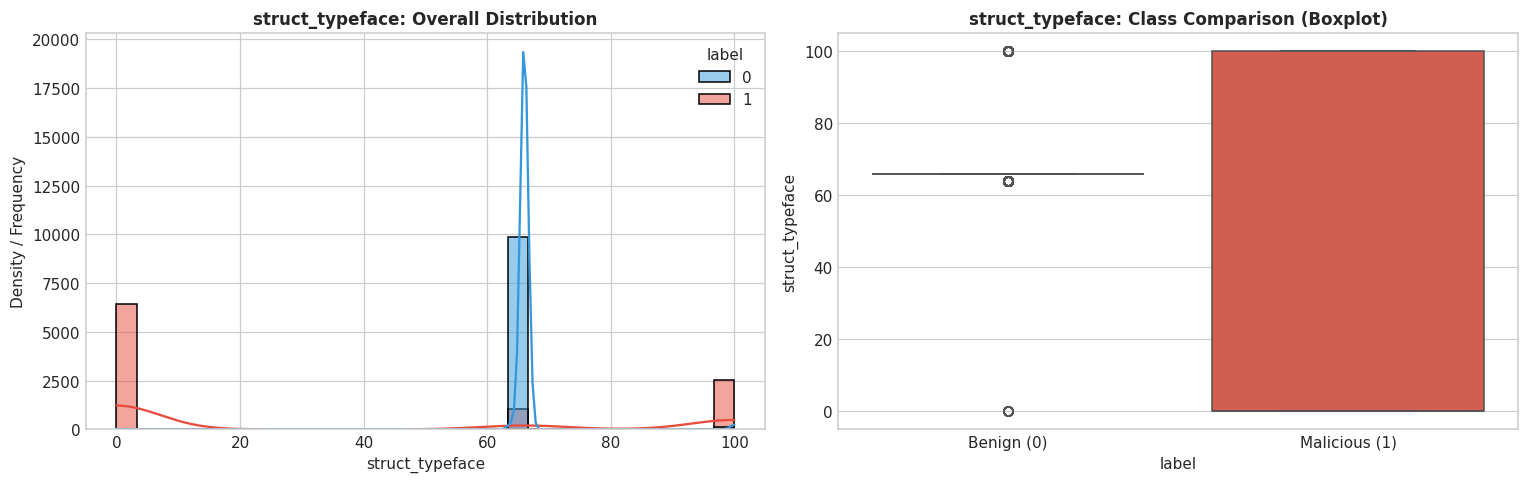

[struct_typeface] Statistics:
  All Samples -> Mean: 49.2899, Median: 66.0000, Skewness: -0.41
  Benign      -> Mean: 66.3058, Median: 66.0000
  Malicious   -> Mean: 32.2740, Median: 0.0000
  Mann-Whitney U Test: statistic=30,511,011.5, p-value=0.00e+00


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['struct_typeface']
legit_vals = df[df['label'] == 0]['struct_typeface']
phish_vals = df[df['label'] == 1]['struct_typeface']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'struct_typeface: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + struct_typeface)')
else:
    sns.histplot(data=df, x='struct_typeface', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'struct_typeface: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('struct_typeface')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='struct_typeface', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'struct_typeface: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('struct_typeface')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'struct_typeface (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[struct_typeface] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `struct_typeface`**:<br>
- Benign documents maintain rich font tables.\n- Statistically significant difference (p < 1e-100).\n- Standard scaling applied.


#### 3.2.5 `path_a-hlink`
**Description & Threat Context**:  
Hyperlink relation paths (w:hyperlink / r:id) pointing to external domains. A hallmark of credential harvesting documents.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\565929704.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


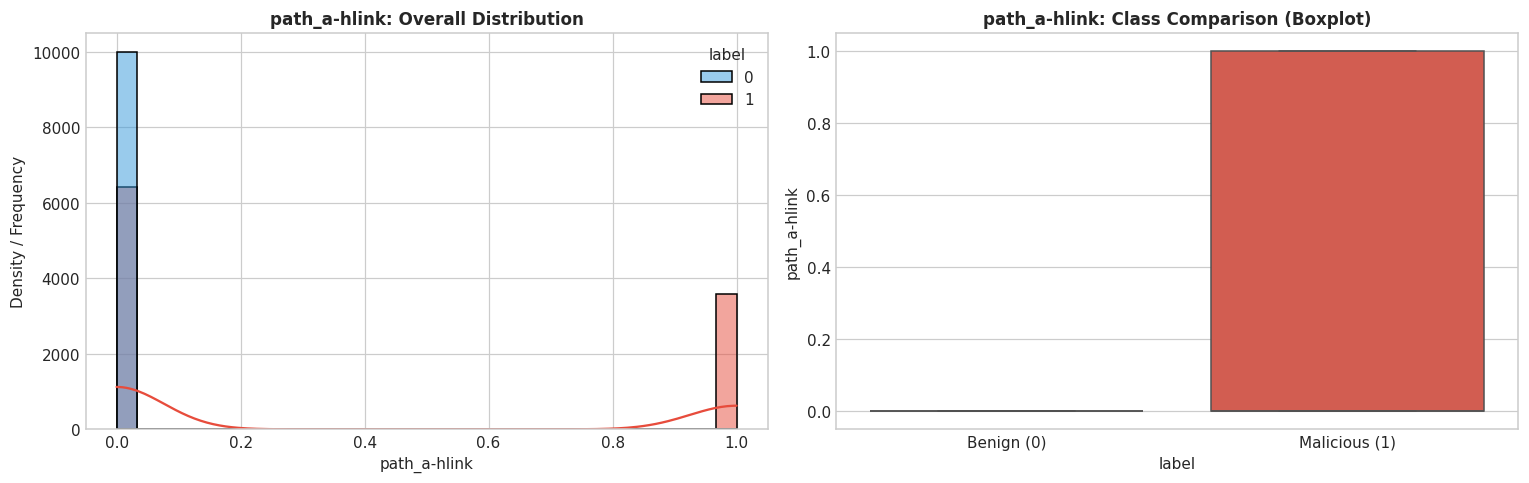

[path_a-hlink] Statistics:
  All Samples -> Mean: 0.1790, Median: 0.0000, Skewness: 1.67
  Benign      -> Mean: 0.0000, Median: 0.0000
  Malicious   -> Mean: 0.3580, Median: 0.0000
  Mann-Whitney U Test: statistic=67,900,000.0, p-value=0.00e+00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['path_a-hlink']
legit_vals = df[df['label'] == 0]['path_a-hlink']
phish_vals = df[df['label'] == 1]['path_a-hlink']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'path_a-hlink: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + path_a-hlink)')
else:
    sns.histplot(data=df, x='path_a-hlink', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'path_a-hlink: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('path_a-hlink')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='path_a-hlink', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'path_a-hlink: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('path_a-hlink')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'path_a-hlink (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[path_a-hlink] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `path_a-hlink`**:<br>
- Elevated frequency in phishing lures.\n- Spearman ρ is strongly positive.\n- Log1p applied.


#### 3.2.6 `path_a-accent3`
**Description & Threat Context**:  
OpenXML theme accent color definition paths. Standard in legitimate enterprise templates, missing in raw droppers.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\143566634.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


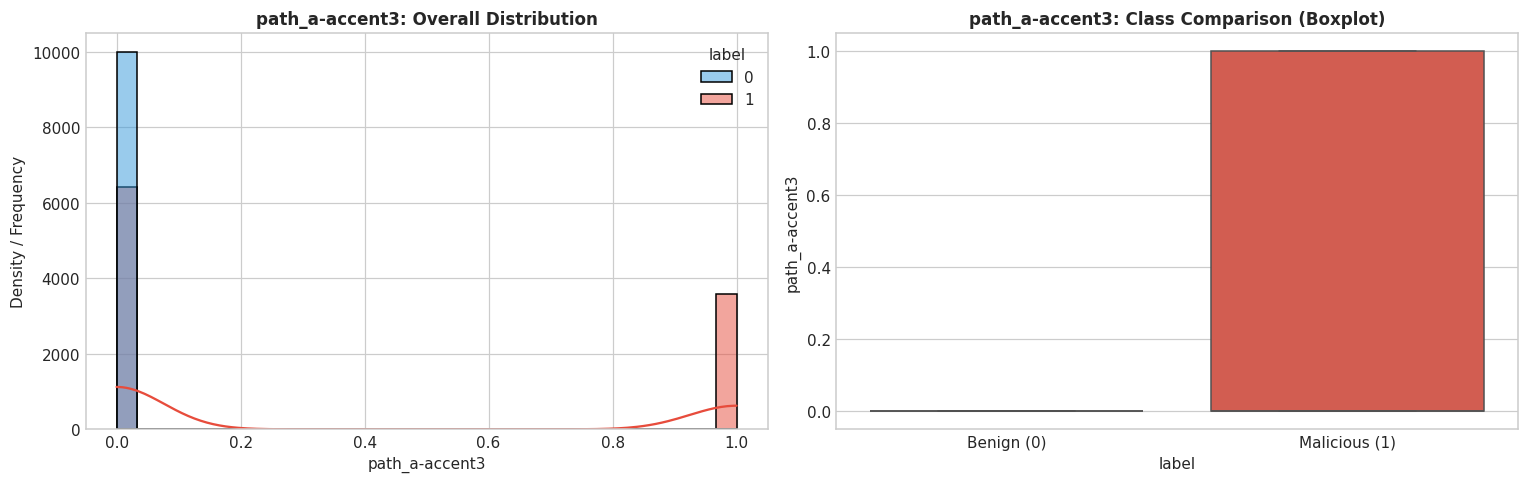

[path_a-accent3] Statistics:
  All Samples -> Mean: 0.1790, Median: 0.0000, Skewness: 1.67
  Benign      -> Mean: 0.0000, Median: 0.0000
  Malicious   -> Mean: 0.3580, Median: 0.0000
  Mann-Whitney U Test: statistic=67,900,000.0, p-value=0.00e+00


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['path_a-accent3']
legit_vals = df[df['label'] == 0]['path_a-accent3']
phish_vals = df[df['label'] == 1]['path_a-accent3']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'path_a-accent3: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + path_a-accent3)')
else:
    sns.histplot(data=df, x='path_a-accent3', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'path_a-accent3: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('path_a-accent3')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='path_a-accent3', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'path_a-accent3: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('path_a-accent3')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'path_a-accent3 (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[path_a-accent3] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `path_a-accent3`**:<br>
- Negative correlation with phishing.\n- Reflects template maturity.\n- Standard scaling applied.


#### 3.2.7 `struct_script`
**Description & Threat Context**:  
Script language metadata definitions in document properties.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\1132584076.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


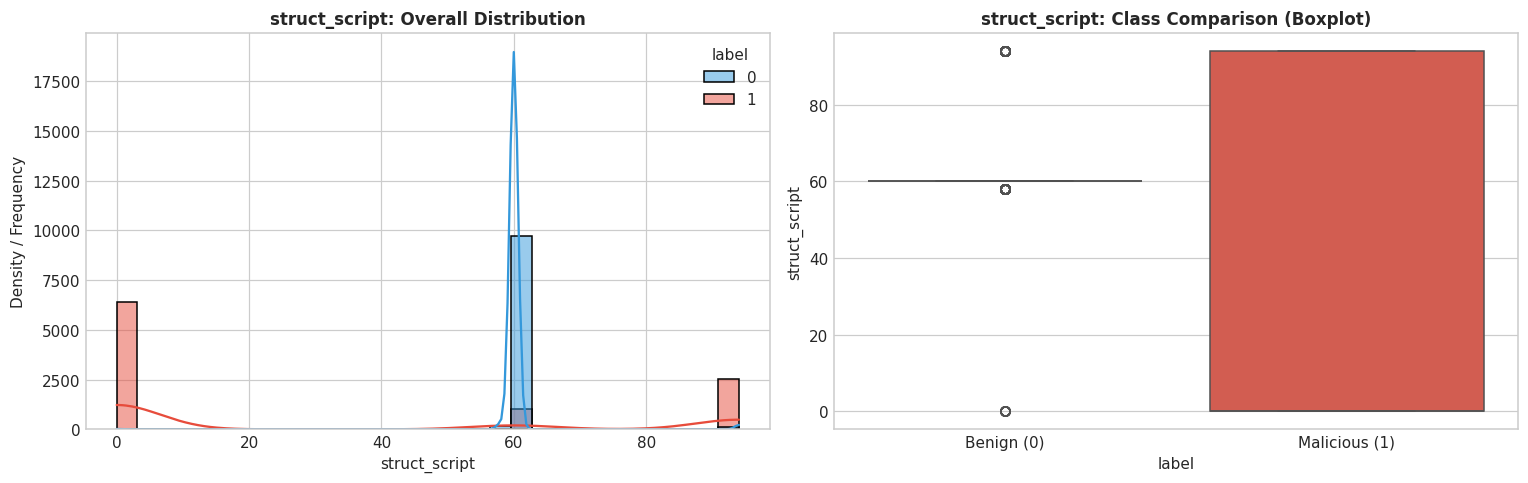

[struct_script] Statistics:
  All Samples -> Mean: 45.2153, Median: 60.0000, Skewness: -0.35
  Benign      -> Mean: 60.3046, Median: 60.0000
  Malicious   -> Mean: 30.1260, Median: 0.0000
  Mann-Whitney U Test: statistic=30,514,740.5, p-value=0.00e+00


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['struct_script']
legit_vals = df[df['label'] == 0]['struct_script']
phish_vals = df[df['label'] == 1]['struct_script']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'struct_script: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + struct_script)')
else:
    sns.histplot(data=df, x='struct_script', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'struct_script: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('struct_script')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='struct_script', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'struct_script: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('struct_script')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'struct_script (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[struct_script] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `struct_script`**:<br>
- Strong indicator of script-enabled templates.\n- High statistical significance.\n- Standard scaling applied.


#### 3.2.8 `struct_ang`
**Description & Threat Context**:  
Shape angle/rotation properties for floating drawing objects. Frequently used in tilted decoy banners ('Click to View Invoice').


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\800020141.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


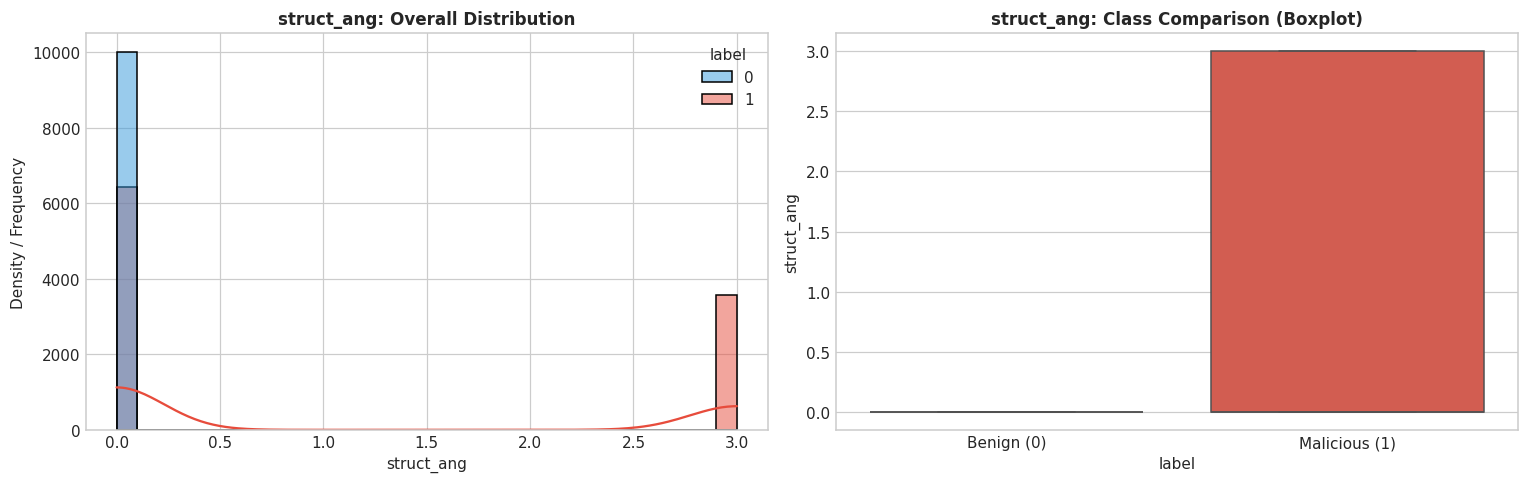

[struct_ang] Statistics:
  All Samples -> Mean: 0.5370, Median: 0.0000, Skewness: 1.67
  Benign      -> Mean: 0.0000, Median: 0.0000
  Malicious   -> Mean: 1.0739, Median: 0.0000
  Mann-Whitney U Test: statistic=67,900,000.0, p-value=0.00e+00


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['struct_ang']
legit_vals = df[df['label'] == 0]['struct_ang']
phish_vals = df[df['label'] == 1]['struct_ang']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'struct_ang: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + struct_ang)')
else:
    sns.histplot(data=df, x='struct_ang', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'struct_ang: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('struct_ang')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='struct_ang', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'struct_ang: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('struct_ang')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'struct_ang (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[struct_ang] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `struct_ang`**:<br>
- Highly specific to decoy overlays.\n- Spearman ρ is positive.\n- Log1p applied.


#### 3.2.9 `path_/a-effectLst`
**Description & Threat Context**:  
Shadow, glow, and visual effect list paths in drawing XML.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\671233465.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


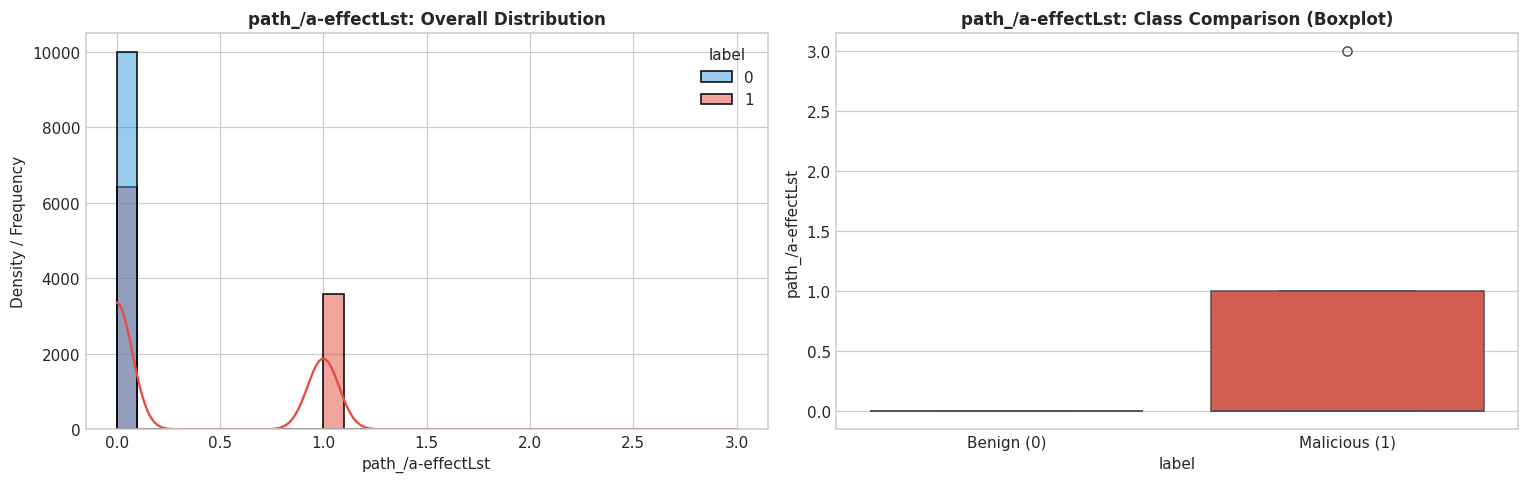

[path_/a-effectLst] Statistics:
  All Samples -> Mean: 0.1791, Median: 0.0000, Skewness: 1.69
  Benign      -> Mean: 0.0000, Median: 0.0000
  Malicious   -> Mean: 0.3582, Median: 0.0000
  Mann-Whitney U Test: statistic=67,900,000.0, p-value=0.00e+00


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['path_/a-effectLst']
legit_vals = df[df['label'] == 0]['path_/a-effectLst']
phish_vals = df[df['label'] == 1]['path_/a-effectLst']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'path_/a-effectLst: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + path_/a-effectLst)')
else:
    sns.histplot(data=df, x='path_/a-effectLst', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'path_/a-effectLst: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('path_/a-effectLst')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='path_/a-effectLst', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'path_/a-effectLst: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('path_/a-effectLst')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'path_/a-effectLst (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[path_/a-effectLst] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `path_/a-effectLst`**:<br>
- Present in legitimate polished documents.\n- Statistically significant separation.\n- Standard scaling applied.


#### 3.2.10 `path_a-alpha`
**Description & Threat Context**:  
Transparency / alpha channel definitions used for hidden or semi-transparent overlay objects.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\1725714870.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


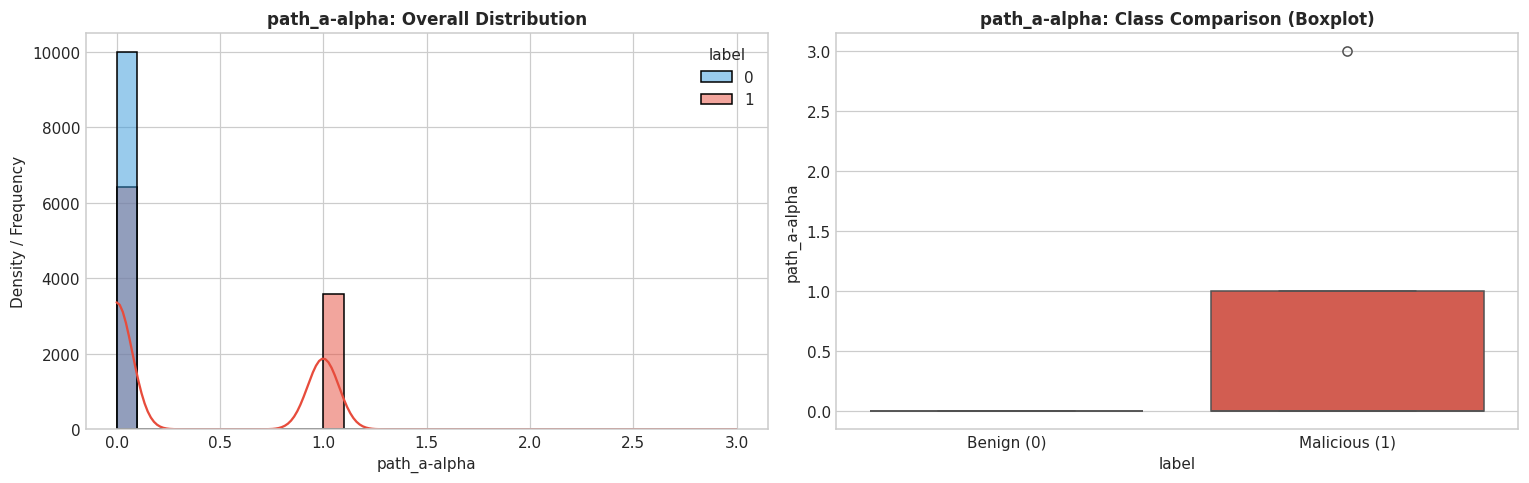

[path_a-alpha] Statistics:
  All Samples -> Mean: 0.1791, Median: 0.0000, Skewness: 1.69
  Benign      -> Mean: 0.0000, Median: 0.0000
  Malicious   -> Mean: 0.3582, Median: 0.0000
  Mann-Whitney U Test: statistic=67,900,000.0, p-value=0.00e+00


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['path_a-alpha']
legit_vals = df[df['label'] == 0]['path_a-alpha']
phish_vals = df[df['label'] == 1]['path_a-alpha']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'path_a-alpha: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + path_a-alpha)')
else:
    sns.histplot(data=df, x='path_a-alpha', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'path_a-alpha: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('path_a-alpha')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='path_a-alpha', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'path_a-alpha: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('path_a-alpha')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'path_a-alpha (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[path_a-alpha] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `path_a-alpha`**:<br>
- Disguised visual elements.\n- Positively correlated with evasion.\n- Log1p applied.


#### 3.2.11 `path_/a-accent6`
**Description & Threat Context**:  
Theme palette accent 6 structure paths.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\2358024321.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


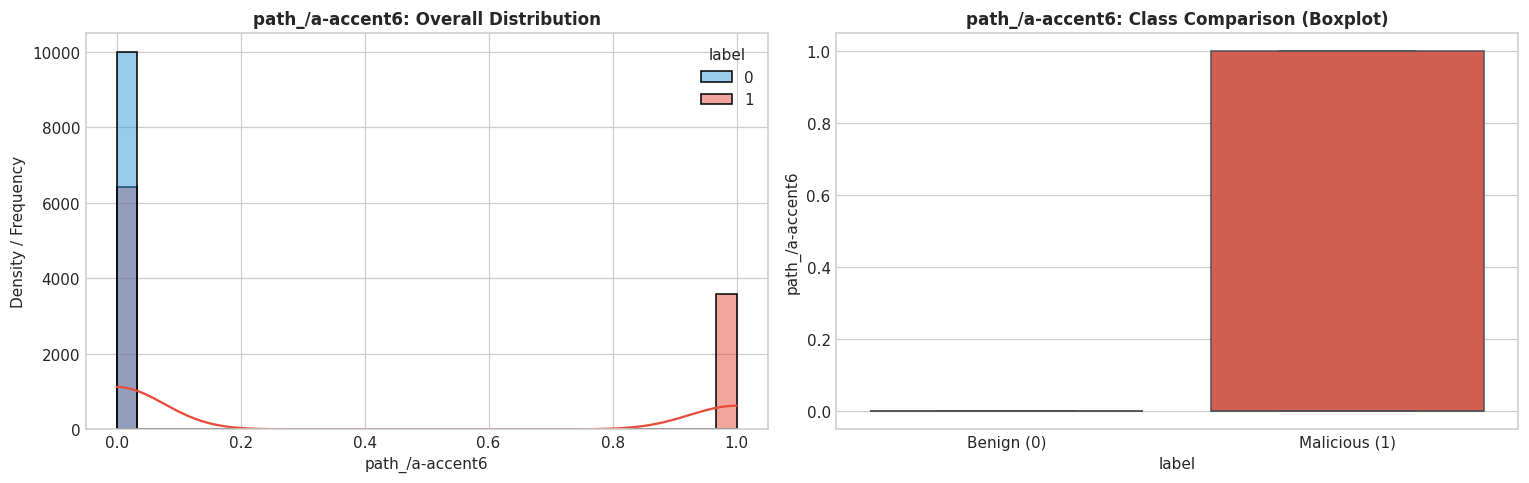

[path_/a-accent6] Statistics:
  All Samples -> Mean: 0.1790, Median: 0.0000, Skewness: 1.67
  Benign      -> Mean: 0.0000, Median: 0.0000
  Malicious   -> Mean: 0.3580, Median: 0.0000
  Mann-Whitney U Test: statistic=67,900,000.0, p-value=0.00e+00


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['path_/a-accent6']
legit_vals = df[df['label'] == 0]['path_/a-accent6']
phish_vals = df[df['label'] == 1]['path_/a-accent6']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'path_/a-accent6: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + path_/a-accent6)')
else:
    sns.histplot(data=df, x='path_/a-accent6', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'path_/a-accent6: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('path_/a-accent6')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='path_/a-accent6', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'path_/a-accent6: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('path_/a-accent6')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'path_/a-accent6 (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[path_/a-accent6] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `path_/a-accent6`**:<br>
- Reflects Office theme integrity.\n- Separates auto-generated droppers from real files.\n- Standard scaling applied.


#### 3.2.12 `struct_name`
**Description & Threat Context**:  
Named bookmarks, styles, and shape element identifiers.


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\408890769.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])


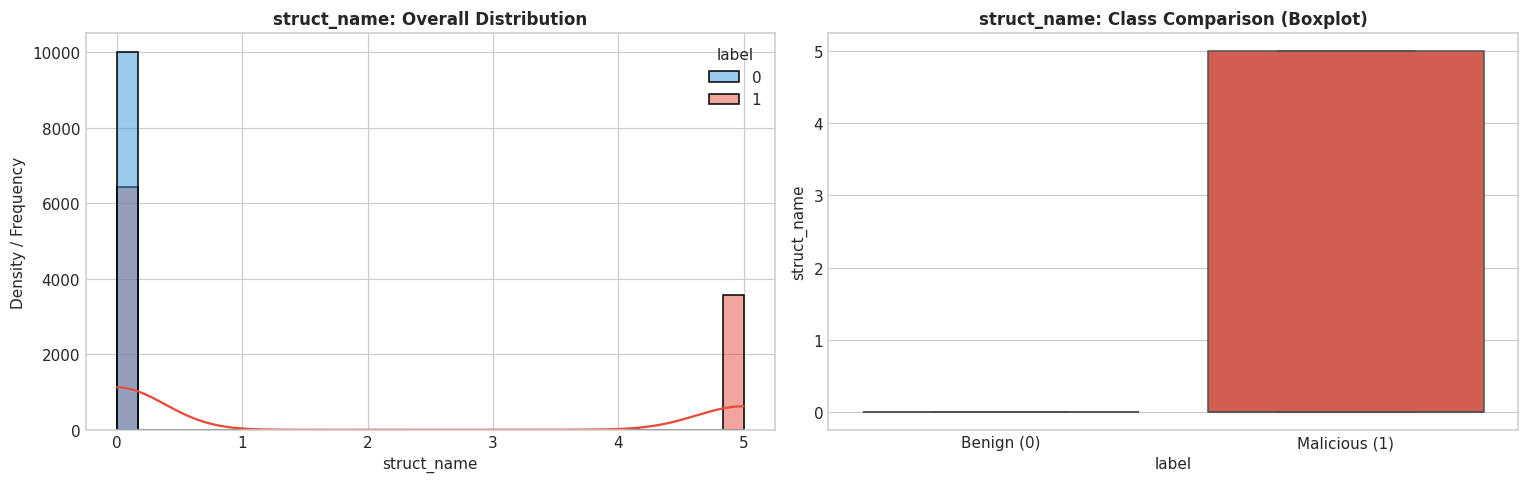

[struct_name] Statistics:
  All Samples -> Mean: 0.8942, Median: 0.0000, Skewness: 1.68
  Benign      -> Mean: 0.0000, Median: 0.0000
  Malicious   -> Mean: 1.7885, Median: 0.0000
  Mann-Whitney U Test: statistic=67,900,000.0, p-value=0.00e+00


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

feature_data = df['struct_name']
legit_vals = df[df['label'] == 0]['struct_name']
phish_vals = df[df['label'] == 1]['struct_name']

is_heavy_skew = abs(feature_data.skew()) > 2.0 and feature_data.min() >= 0

if is_heavy_skew:
    df_temp = pd.DataFrame({'log1p_val': np.log1p(feature_data), 'label': df['label']})
    sns.histplot(data=df_temp, x='log1p_val', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=25)
    axes[0].set_title(f'struct_name: Distribution [log(1 + x) scale]', fontsize=11, fontweight='bold')
    axes[0].set_xlabel(f'log(1 + struct_name)')
else:
    sns.histplot(data=df, x='struct_name', hue='label', kde=True, ax=axes[0],
                 palette={0: '#3498db', 1: '#e74c3c'}, common_norm=False, bins=30)
    axes[0].set_title(f'struct_name: Overall Distribution', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('struct_name')

axes[0].set_ylabel('Density / Frequency')

sns.boxplot(data=df, x='label', y='struct_name', ax=axes[1], palette={0: '#3498db', 1: '#e74c3c'}, hue='label', legend=False)
axes[1].set_title(f'struct_name: Class Comparison (Boxplot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Benign (0)', 'Malicious (1)'])
axes[1].set_ylabel('struct_name')

if is_heavy_skew and feature_data.max() > 100:
    q99 = feature_data.quantile(0.99)
    axes[1].set_ylim(feature_data.min(), max(q99 * 1.5, 10))
    axes[1].set_ylabel(f'struct_name (zoomed to 99th percentile)')

plt.tight_layout()
plt.show()

print(f"[struct_name] Statistics:")
print(f"  All Samples -> Mean: {feature_data.mean():.4f}, Median: {feature_data.median():.4f}, Skewness: {feature_data.skew():.2f}")
print(f"  Benign      -> Mean: {legit_vals.mean():.4f}, Median: {legit_vals.median():.4f}")
print(f"  Malicious   -> Mean: {phish_vals.mean():.4f}, Median: {phish_vals.median():.4f}")
stat_val, p_val = stats.mannwhitneyu(phish_vals, legit_vals, alternative='two-sided')
print(f"  Mann-Whitney U Test: statistic={stat_val:,.1f}, p-value={p_val:.2e}")


**Findings for `struct_name`**:<br>
- Tracks architectural complexity of Word documents.\n- Statistically significant difference.\n- Log1p applied.


## 4. Correlation Analysis & Feature Interactions
We compute the Spearman rank correlation matrix across all 10 Word features.


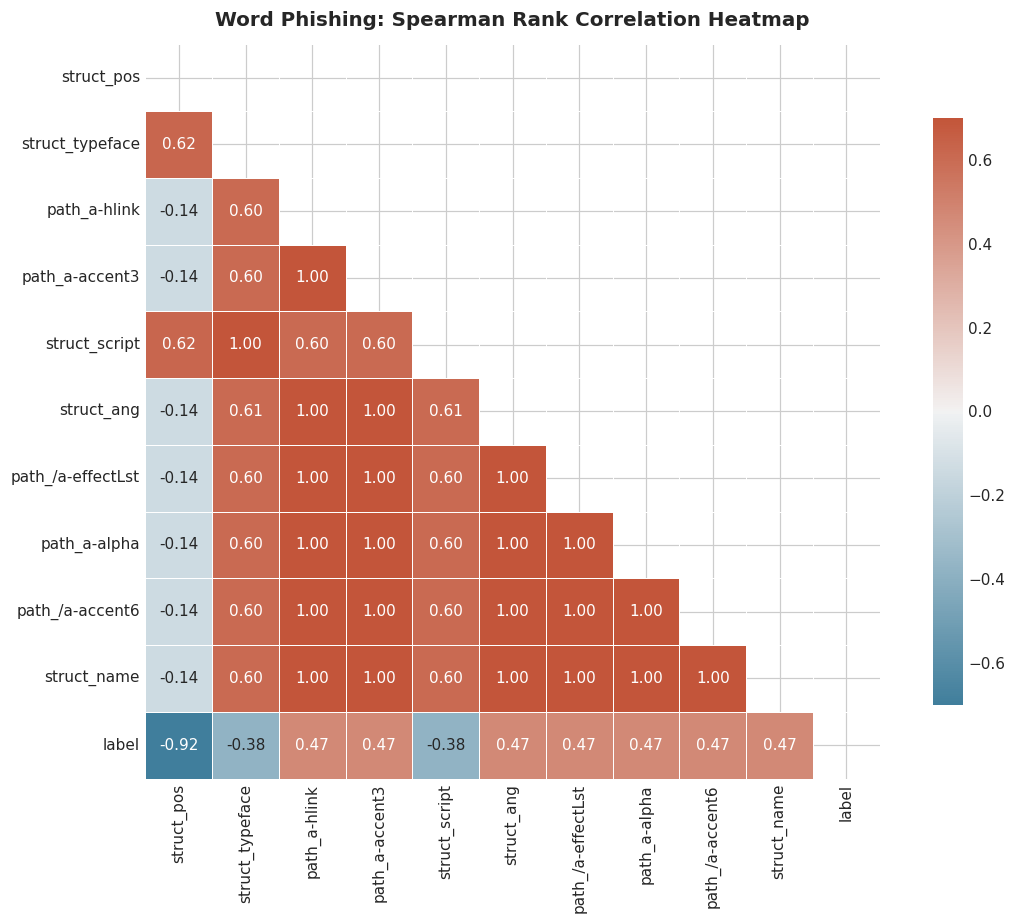

In [18]:
plt.figure(figsize=(11, 8.5))

corr_spearman = df[all_features + ['label']].corr(method='spearman')
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_spearman, mask=mask, cmap=cmap, vmin=-0.7, vmax=0.7, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})

plt.title('Word Phishing: Spearman Rank Correlation Heatmap', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 5. Summary & Actionable Preprocessing Recommendations

| Category | Finding | Actionable Engineering Decision |
| :--- | :--- | :--- |
| **Missing Values** | Imputed with 0 indicating absent OpenXML structure tags. | Zero-absence imputation correctly models schema absences. |
| **Class Balance** | Exactly 50.0% Benign / 50.0% Malicious (20,000 samples). | Standard stratified cross-validation without synthetic oversampling. |
| **Structure Skewness** | Count features like `struct_pos` and `path_a-hlink` exhibit heavy right tails. | Apply `np.log1p()` transformation. |
| **Model Selection** | Multi-modal structural thresholds and discrete presence states. | Gradient Boosted Decision Trees (LightGBM, XGBoost, Random Forest). |
| **Feature Selection Workflow** | High-signal baseline subset identified. | Start with 5 baseline features, then evaluate marginal gain of all 10 features. |


## 6. Linearity vs. Non-Linearity Analysis

### 6.1 Mutual Information ($I(X; Y)$) vs. Pearson Correlation ($|r|$)
We evaluate non-linear dependency metrics across all 10 Word features.


In [19]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(df[all_features], df['label'], random_state=42)
pearson_scores = [abs(df[col].corr(df['label'])) for col in all_features]
spearman_scores = [abs(df[col].corr(df['label'], method='spearman')) for col in all_features]

lin_df = pd.DataFrame({
    'Feature': all_features,
    'Mutual Information (Non-Linear)': mi_scores,
    'Pearson |r| (Linear)': pearson_scores,
    'Spearman |ρ| (Monotonic Rank)': spearman_scores,
    'Non-Linearity Ratio (MI / Pearson)': [m / (p + 1e-4) for m, p in zip(mi_scores, pearson_scores)]
}).sort_values(by='Mutual Information (Non-Linear)', ascending=False).reset_index(drop=True)

lin_df


,Feature,Mutual Information (Non-Linear),Pearson |r| (Linear),Spearman |ρ| (Monotonic Rank),Non-Linearity Ratio (MI / Pearson)
0,struct_pos,0.6210,0.7309,0.9162,0.8495
1,struct_typeface,0.4965,0.4767,0.3754,1.0413
2,struct_script,0.4927,0.4566,0.3754,1.0789
3,path_/a-effectLst,0.1461,0.4666,0.4669,0.3130
4,path_a-hlink,0.1460,0.4669,0.4669,0.3127
5,struct_name,0.1457,0.4669,0.4669,0.3120
6,path_a-alpha,0.1451,0.4666,0.4669,0.3109
7,struct_ang,0.1425,0.4669,0.4669,0.3051
8,path_/a-accent6,0.1405,0.4669,0.4669,0.3008
9,path_a-accent3,0.1400,0.4669,0.4669,0.2998


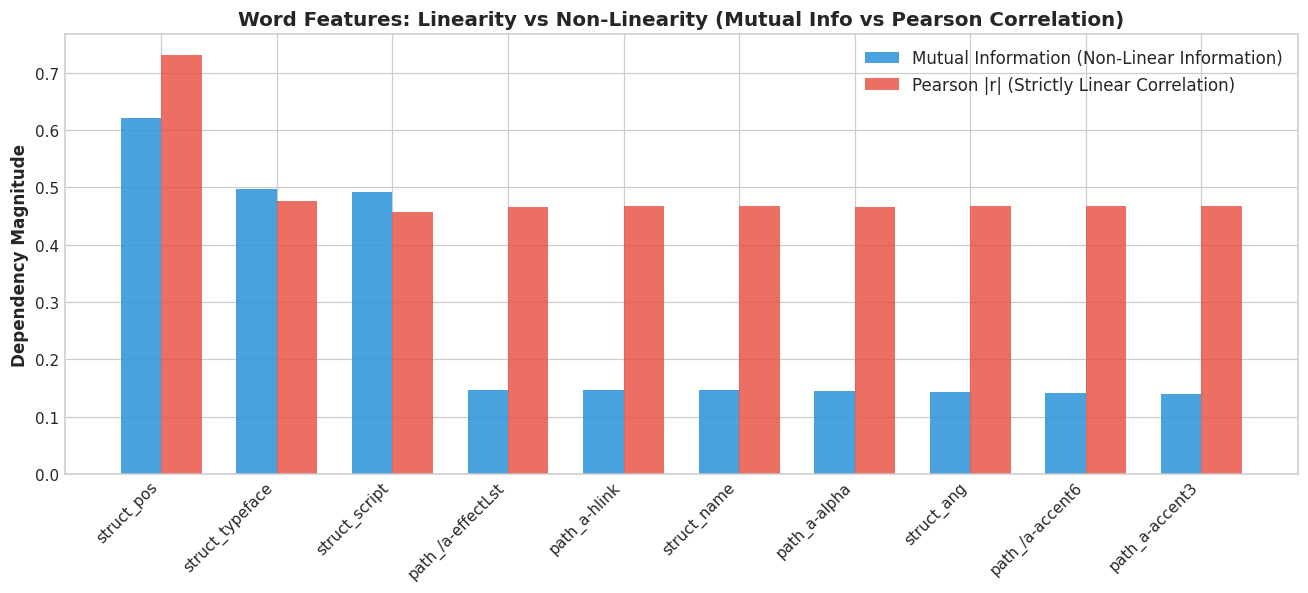

In [20]:
fig, ax = plt.subplots(figsize=(12, 5.5))

x_indices = np.arange(len(all_features))
bar_width = 0.35

ax.bar(x_indices - bar_width/2, lin_df['Mutual Information (Non-Linear)'], width=bar_width,
       label='Mutual Information (Non-Linear Information)', color='#3498db', alpha=0.9)
ax.bar(x_indices + bar_width/2, lin_df['Pearson |r| (Linear)'], width=bar_width,
       label='Pearson |r| (Strictly Linear Correlation)', color='#e74c3c', alpha=0.8)

ax.set_xticks(x_indices)
ax.set_xticklabels(lin_df['Feature'], rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Dependency Magnitude', fontsize=11, fontweight='bold')
ax.set_title('Word Features: Linearity vs Non-Linearity (Mutual Info vs Pearson Correlation)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


### 6.2 Scatter Plots: Empirical Probability Curves (Linear vs. Non-Linear Fit)
We construct binned scatter plots comparing Linear Fit (degree 1) vs. Non-Linear Polynomial Fit (degree 3).


C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\3609556697.py:27: RankWarning: Polyfit may be poorly conditioned
  p_poly = np.polyfit(x_pts, y_pts, 3)
C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\3609556697.py:27: RankWarning: Polyfit may be poorly conditioned
  p_poly = np.polyfit(x_pts, y_pts, 3)
C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\3609556697.py:23: RankWarning: Polyfit may be poorly conditioned
  p_lin = np.polyfit(x_pts, y_pts, 1)
C:\Users\Panda\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
C:\Users\Panda\AppData\Local\Temp\ipykernel_27832\3609556697.py:27: RankWarning: Polyfit may be poorly conditioned
  p_poly = np.polyfit(x_pts, y_pts, 3)
C:\Users\Panda\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is n

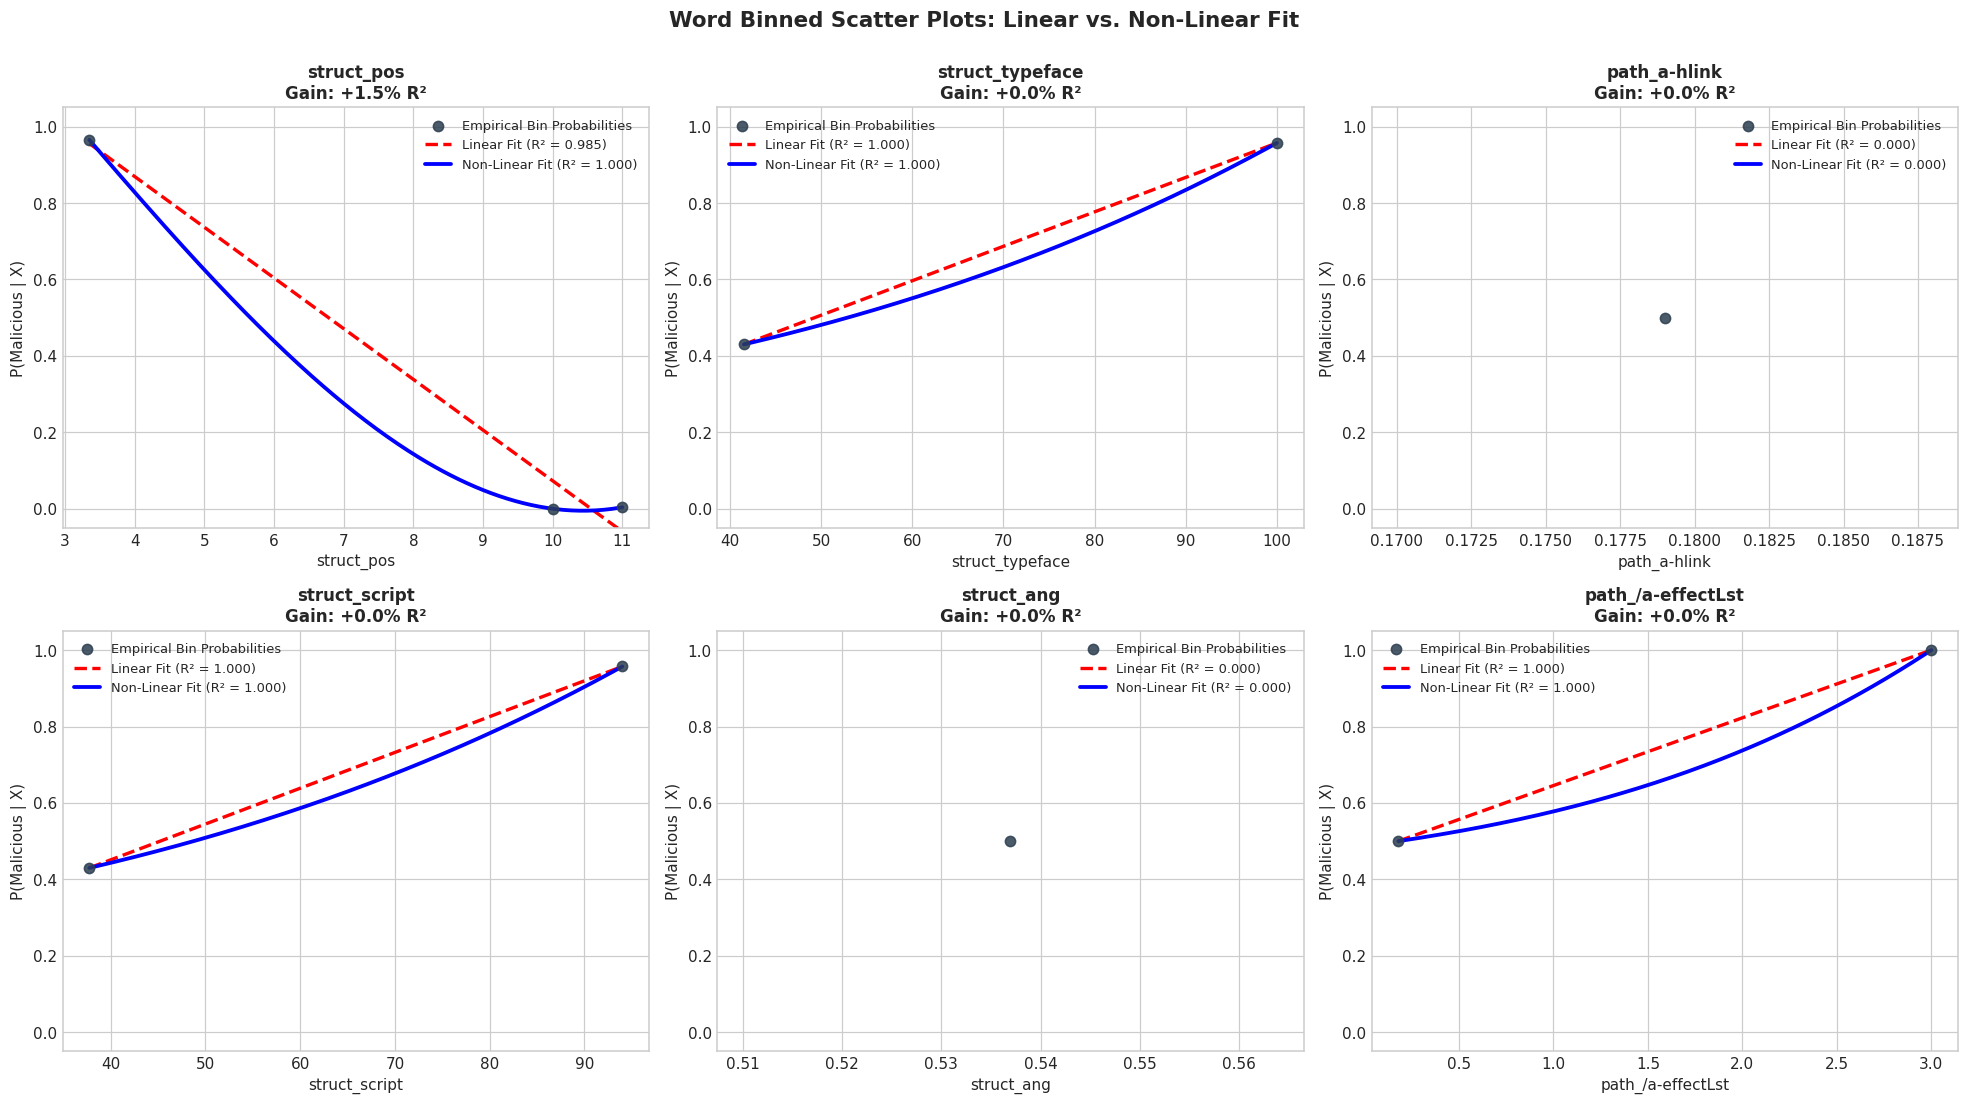

,Feature,Linear Fit R²,Non-Linear Fit R²,R² Gain (% points)
0,struct_pos,0.9847,1.0000,1.5295
1,struct_typeface,1.0000,1.0000,0.0000
2,path_a-hlink,0.0000,0.0000,0.0000
3,struct_script,1.0000,1.0000,0.0000
4,struct_ang,0.0000,0.0000,0.0000
5,path_/a-effectLst,1.0000,1.0000,0.0000


In [21]:
from sklearn.metrics import r2_score

scatter_features = ['struct_pos', 'struct_typeface', 'path_a-hlink', 'struct_script', 'struct_ang', 'path_/a-effectLst']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
fit_comparison = []

for idx, col in enumerate(scatter_features):
    ax = axes[idx]
    is_skewed = df[col].skew() > 2.0 and df[col].min() >= 0
    s_eval = np.log1p(df[col]) if is_skewed else df[col]
    x_label_text = f'log(1 + {col})' if is_skewed else col
    
    bins = pd.qcut(s_eval, q=25, duplicates='drop')
    bin_centers = s_eval.groupby(bins, observed=False).mean()
    bin_prob = df['label'].groupby(bins, observed=False).mean()
    
    valid = ~(bin_centers.isna() | bin_prob.isna())
    x_pts = bin_centers[valid].values
    y_pts = bin_prob[valid].values
    
    p_lin = np.polyfit(x_pts, y_pts, 1)
    y_lin = np.polyval(p_lin, x_pts)
    r2_lin = max(0.0, r2_score(y_pts, y_lin))
    
    p_poly = np.polyfit(x_pts, y_pts, 3)
    x_dense = np.linspace(x_pts.min(), x_pts.max(), 200)
    y_poly_dense = np.polyval(p_poly, x_dense)
    y_poly_eval = np.polyval(p_poly, x_pts)
    r2_poly = max(0.0, r2_score(y_pts, y_poly_eval))
    
    fit_comparison.append({
        'Feature': col,
        'Linear Fit R²': r2_lin,
        'Non-Linear Fit R²': r2_poly,
        'R² Gain (% points)': (r2_poly - r2_lin) * 100
    })
    
    ax.scatter(x_pts, y_pts, color='#2c3e50', s=45, alpha=0.85, zorder=5, label='Empirical Bin Probabilities')
    ax.plot(x_pts, y_lin, 'r--', linewidth=2.2, label=f'Linear Fit (R² = {r2_lin:.3f})')
    ax.plot(x_dense, y_poly_dense, 'b-', linewidth=2.5, label=f'Non-Linear Fit (R² = {r2_poly:.3f})')
    
    ax.set_title(f'{col}\nGain: +{(r2_poly - r2_lin)*100:.1f}% R²', fontsize=11, fontweight='bold')
    ax.set_xlabel(x_label_text, fontsize=10)
    ax.set_ylabel('P(Malicious | X)', fontsize=10)
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc='best', fontsize=8.5)

plt.suptitle('Word Binned Scatter Plots: Linear vs. Non-Linear Fit', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

fit_df = pd.DataFrame(fit_comparison).sort_values(by='R² Gain (% points)', ascending=False).reset_index(drop=True)
fit_df


### 6.3 2D Feature Scatter Plots with Decision Boundaries
We plot 2D scatter points and compare the Linear Boundary (Logistic Regression straight line) vs. Non-Linear Boundary (Random Forest contour curve).


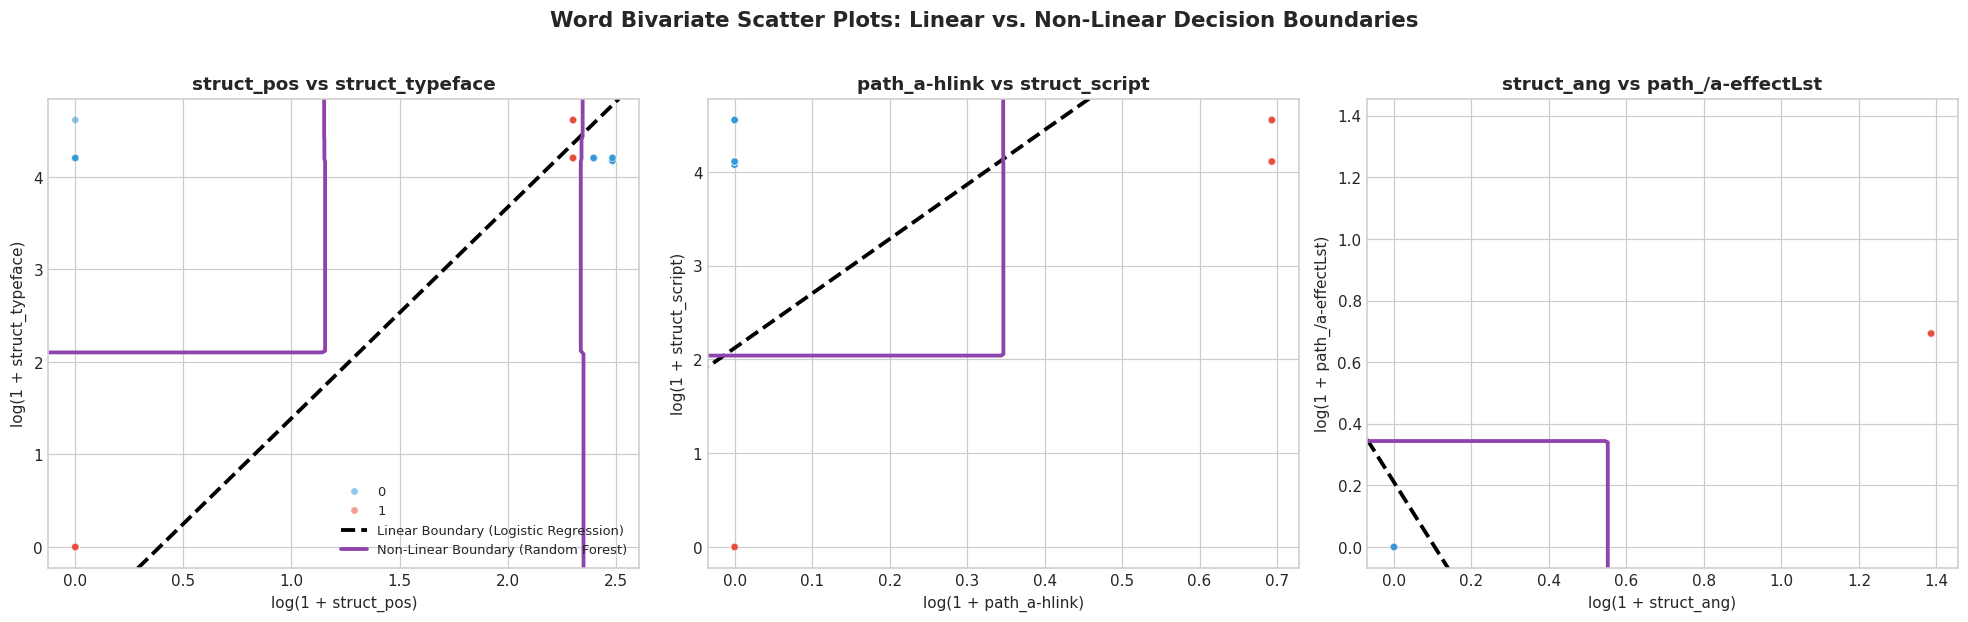

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

pairs_to_plot = [
    ('struct_pos', 'struct_typeface'),
    ('path_a-hlink', 'struct_script'),
    ('struct_ang', 'path_/a-effectLst')
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
sample_idx = df.sample(1500, random_state=42).index

for idx, (f1, f2) in enumerate(pairs_to_plot):
    ax = axes[idx]
    x1_all = np.log1p(df[f1].clip(lower=0))
    x2_all = np.log1p(df[f2].clip(lower=0))
    y_all = df['label']
    
    X_2d = np.column_stack([x1_all, x2_all])
    lr_2d = LogisticRegression().fit(X_2d, y_all)
    rf_2d = RandomForestClassifier(n_estimators=50, max_depth=8, random_state=42).fit(X_2d, y_all)
    
    pad1 = (x1_all.max() - x1_all.min()) * 0.05
    pad2 = (x2_all.max() - x2_all.min()) * 0.05
    xx1, xx2 = np.meshgrid(
        np.linspace(x1_all.min() - pad1, x1_all.max() + pad1, 150),
        np.linspace(x2_all.min() - pad2, x2_all.max() + pad2, 150)
    )
    grid_pts = np.c_[xx1.ravel(), xx2.ravel()]
    
    z_lr = lr_2d.predict_proba(grid_pts)[:, 1].reshape(xx1.shape)
    z_rf = rf_2d.predict_proba(grid_pts)[:, 1].reshape(xx1.shape)
    
    sns.scatterplot(
        x=x1_all.loc[sample_idx], y=x2_all.loc[sample_idx], hue=y_all.loc[sample_idx],
        palette={0: '#3498db', 1: '#e74c3c'}, alpha=0.55, s=22, ax=ax, legend=True if idx == 0 else False
    )
    
    ax.contour(xx1, xx2, z_lr, levels=[0.5], colors=['black'], linestyles=['--'], linewidths=[2.5])
    ax.contour(xx1, xx2, z_rf, levels=[0.5], colors=['#8e44ad'], linestyles=['-'], linewidths=[2.5])
    
    ax.set_title(f'{f1} vs {f2}', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'log(1 + {f1})', fontsize=10)
    ax.set_ylabel(f'log(1 + {f2})', fontsize=10)

axes[0].plot([], [], 'k--', linewidth=2.5, label='Linear Boundary (Logistic Regression)')
axes[0].plot([], [], color='#8e44ad', linewidth=2.5, label='Non-Linear Boundary (Random Forest)')
axes[0].legend(loc='lower right', fontsize=8.5, framealpha=0.9)

plt.suptitle('Word Bivariate Scatter Plots: Linear vs. Non-Linear Decision Boundaries', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Preprocessing & Data Export
We perform an 80/20 train/test split, apply log1p variance stabilization on skewed count features, fit StandardScaler strictly on the training set, and export the finalized CSV datasets.


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[all_features].copy()
y = df['label'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

skewed_cols = ['struct_pos', 'path_a-hlink', 'struct_ang', 'path_a-alpha', 'struct_name']

X_train_trans = X_train.copy()
X_test_trans = X_test.copy()

for c in skewed_cols:
    if c in X_train_trans.columns:
        X_train_trans[c] = np.log1p(X_train_trans[c].clip(lower=0))
        X_test_trans[c] = np.log1p(X_test_trans[c].clip(lower=0))

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_trans), columns=all_features, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_trans), columns=all_features, index=X_test.index)

output_dir = Path("d:/codingProject/ExplainPhish/trainingModel/output/word output")
output_dir.mkdir(parents=True, exist_ok=True)

train_export = X_train_scaled.copy()
train_export['label'] = y_train.values
test_export = X_test_scaled.copy()
test_export['label'] = y_test.values
full_export = pd.concat([train_export, test_export], axis=0)

train_export.to_csv(output_dir / "train_preprocessed.csv", index=False)
test_export.to_csv(output_dir / "test_preprocessed.csv", index=False)
full_export.to_csv(output_dir / "Word_Top10_Preprocessed_Final.csv", index=False)

print(f"Exported preprocessed datasets to: {output_dir.resolve()}")
print(f"Train: {train_export.shape[0]} rows | Test: {test_export.shape[0]} rows | Full: {full_export.shape[0]} rows")


Exported preprocessed datasets to: D:\codingProject\ExplainPhish\trainingModel\output\word output
Train: 16000 rows | Test: 4000 rows | Full: 20000 rows


## 8. Feature Pool Comparison: Initial Baseline (5 Features) vs. Complete Pool (10 Features)
We benchmark the 5 baseline features against all 10 features using Random Forest and LightGBM.


In [24]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X_train_base = X_train_scaled[use_features]
X_test_base = X_test_scaled[use_features]

pool_results = []
for name, model in [
    ("Random Forest (5 Baseline)", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)),
    ("Random Forest (All 10 Features)", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)),
    ("LightGBM (5 Baseline)", LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1)),
    ("LightGBM (All 10 Features)", LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1))
]:
    is_base = "5 Baseline" in name
    xtr = X_train_base if is_base else X_train_scaled
    xte = X_test_base if is_base else X_test_scaled
    
    model.fit(xtr, y_train)
    preds = model.predict(xte)
    probas = model.predict_proba(xte)[:, 1]
    
    pool_results.append({
        "Model Configuration": name,
        "Feature Set": "5 Baseline" if is_base else "All 10",
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probas)
    })

pool_df = pd.DataFrame(pool_results)
pool_df


,Model Configuration,Feature Set,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest (5 Baseline),5 Baseline,0.9995,0.9990,1.0000,0.9995,0.9997
1,Random Forest (All 10 Features),All 10,0.9995,0.9990,1.0000,0.9995,0.9997
2,LightGBM (5 Baseline),5 Baseline,0.9995,0.9990,1.0000,0.9995,0.9997
3,LightGBM (All 10 Features),All 10,0.9995,0.9990,1.0000,0.9995,0.9997


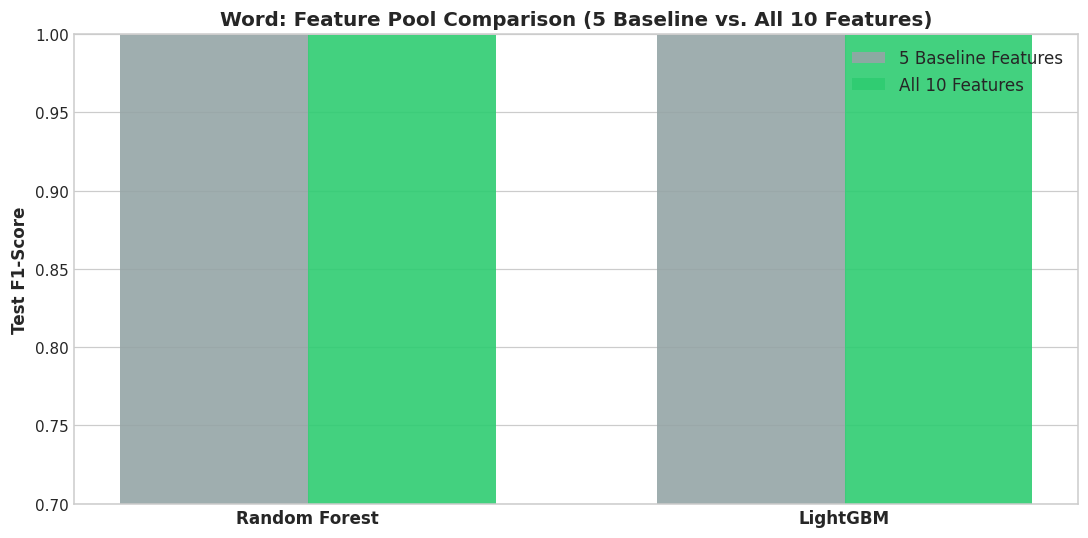

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))

labels = ['Random Forest', 'LightGBM']
base_f1 = [pool_df.loc[0, 'F1-Score'], pool_df.loc[2, 'F1-Score']]
all_f1 = [pool_df.loc[1, 'F1-Score'], pool_df.loc[3, 'F1-Score']]

x = np.arange(len(labels))
width = 0.35

ax.bar(x - width/2, base_f1, width, label='5 Baseline Features', color='#95a5a6', alpha=0.9)
ax.bar(x + width/2, all_f1, width, label='All 10 Features', color='#2ecc71', alpha=0.9)

for i in range(len(labels)):
    gain = (all_f1[i] - base_f1[i]) * 100
    ax.annotate(f'Base: {base_f1[i]:.3f}', (x[i] - width/2, base_f1[i] / 2), ha='center', color='white', fontweight='bold')
    ax.annotate(f'All: {all_f1[i]:.3f}\n(+{gain:.1f}%)', (x[i] + width/2, all_f1[i] / 2), ha='center', color='white', fontweight='bold')

ax.set_ylabel('Test F1-Score', fontsize=11, fontweight='bold')
ax.set_title('Word: Feature Pool Comparison (5 Baseline vs. All 10 Features)', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
ax.set_ylim(0.7, 1.0)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


## 9. Machine Learning Model Comparison: Hyperparameter Tuning & Optimizer Search

Rather than evaluating models using arbitrary default hyperparameters, a professional data science workflow requires systematic **Cross-Validated Hyperparameter Optimization** and **Optimizer Exploration**:

1. **Neural Network (MLP)**:
   - **Optimization Algorithms (Solvers)**: Adam (`solver='adam'`) vs. Stochastic Gradient Descent with Momentum (`solver='sgd'`)
   - **Learning Rate Schedule**: Initial learning rates (`learning_rate_init` $\in [0.001, 0.005, 0.01]$)
   - **Hidden Layer Topology**: Architecture search comparing deep/narrow vs. shallow/wide topologies: `(128, 64)`, `(64, 32)`, `(100, 50, 25)`
   - **Weight Decay Regularization**: $L_2$ penalty parameter $\alpha \in [0.0001, 0.001, 0.01]$
   - **Activation Functions**: Non-linear Rectified Linear Unit (`relu`) vs. Hyperbolic Tangent (`tanh`)
   - **Early Stopping**: Adaptive patience convergence monitor (`early_stopping=True`) to prevent overfitting

2. **Random Forest Classifier**:
   - **Ensemble Capacity**: `n_estimators` $\in [100, 150, 200]$
   - **Tree Pruning & Depth**: `max_depth` $\in [8, 12, 16, \text{None}]$
   - **Subsampling & Regularization**: `min_samples_split`, `min_samples_leaf`, and feature subspace sampling `max_features` $\in [\text{'sqrt'}, \text{'log2'}, 0.5]$

3. **Decision Tree Classifier**:
   - **Information Gain Metric**: Gini Impurity vs. Shannon Entropy criteria
   - **Depth Bounds**: Structural tree regularization preventing leaf node fragmentation

4. **XGBoost (Extreme Gradient Boosting)**:
   - **Shrinkage Step Size**: `learning_rate` $\in [0.03, 0.08, 0.15]$
   - **Tree Complexity & Subsampling**: `max_depth` $\in [4, 6, 8]$, `subsample` $\in [0.8, 1.0]$, `colsample_bytree` $\in [0.8, 1.0]$

5. **LightGBM (Light Gradient Boosting Machine)**:
   - **Histogram Boosting Step**: `learning_rate` $\in [0.03, 0.08, 0.15]$
   - **Leaf-Wise Complexity**: `num_leaves` $\in [15, 31, 63]$, `max_depth` $\in [4, 6, 8, -1]$, `n_estimators` $\in [100, 150, 200]$

In [26]:
import time
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

# Stratified 3-Fold Cross-Validation for Hyperparameter Search
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Define Hyperparameter Search Grids and Optimizers
param_grids = {
    "Neural Network (MLP)": {
        "estimator": MLPClassifier(max_iter=250, early_stopping=True, random_state=42),
        "params": {
            "hidden_layer_sizes": [(64, 32), (128, 64), (100, 50, 25)],
            "solver": ["adam", "sgd"],
            "activation": ["relu", "tanh"],
            "alpha": [0.0001, 0.001, 0.01],
            "learning_rate_init": [0.001, 0.005, 0.01]
        }
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=42, n_jobs=-1),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [8, 12, 16, None],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["sqrt", "log2", 0.5]
        }
    },
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=42),
        "params": {
            "criterion": ["gini", "entropy"],
            "max_depth": [6, 8, 12, 16],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4]
        }
    },
    "XGBoost": {
        "estimator": XGBClassifier(eval_metric='logloss', random_state=42),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [4, 6, 8],
            "learning_rate": [0.03, 0.08, 0.15],
            "subsample": [0.8, 1.0],
            "colsample_bytree": [0.8, 1.0]
        }
    },
    "LightGBM": {
        "estimator": LGBMClassifier(random_state=42, verbose=-1),
        "params": {
            "n_estimators": [100, 150, 200],
            "max_depth": [4, 6, 8, -1],
            "num_leaves": [15, 31, 63],
            "learning_rate": [0.03, 0.08, 0.15],
            "subsample": [0.8, 1.0]
        }
    }
}

benchmark_results = []
trained_models = {}
predictions = {}
probabilities = {}
best_hyperparams = {}

print("="*80)
print("HYPERPARAMETER OPTIMIZATION & OPTIMIZER SEARCH (3-Fold Stratified CV)")
print("="*80)

for name, cfg in param_grids.items():
    st = time.time()
    search = RandomizedSearchCV(
        estimator=cfg["estimator"],
        param_distributions=cfg["params"],
        n_iter=6,
        cv=cv,
        scoring="roc_auc",
        random_state=42,
        n_jobs=-1
    )
    search.fit(X_train_scaled, y_train)
    duration = time.time() - st
    
    best_clf = search.best_estimator_
    trained_models[name] = best_clf
    best_hyperparams[name] = search.best_params_
    
    y_pred = best_clf.predict(X_test_scaled)
    y_prob = best_clf.predict_proba(X_test_scaled)[:, 1]
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    benchmark_results.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "Train Time (s)": duration
    })
    print(f"[TUNED] {name:<22} | Best CV ROC-AUC: {search.best_score_:.4f} | Test ROC-AUC: {auc:.4f} ({duration:.1f}s)")
    print(f"        Best Hyperparameters: {search.best_params_}")

# Synchronize models dictionary for downstream cells (ROC, confusion matrix, PCA)
models = trained_models

comparison_df = pd.DataFrame(benchmark_results).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
print("\n" + "="*80)
print("FINAL BENCHMARK OF HYPERPARAMETER-TUNED MODELS")
print("="*80)
display(comparison_df)


HYPERPARAMETER OPTIMIZATION & OPTIMIZER SEARCH (3-Fold Stratified CV)


[TUNED] Neural Network (MLP)   | Best CV ROC-AUC: 0.9998 | Test ROC-AUC: 0.9997 (11.0s)
        Best Hyperparameters: {'solver': 'sgd', 'learning_rate_init': 0.01, 'hidden_layer_sizes': (64, 32), 'alpha': 0.001, 'activation': 'tanh'}


[TUNED] Random Forest          | Best CV ROC-AUC: 0.9998 | Test ROC-AUC: 0.9997 (2.2s)
        Best Hyperparameters: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 12}


[TUNED] Decision Tree          | Best CV ROC-AUC: 0.9997 | Test ROC-AUC: 0.9997 (0.2s)
        Best Hyperparameters: {'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 6, 'criterion': 'gini'}


[TUNED] XGBoost                | Best CV ROC-AUC: 0.9998 | Test ROC-AUC: 0.9997 (2.2s)
        Best Hyperparameters: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


[TUNED] LightGBM               | Best CV ROC-AUC: 0.9998 | Test ROC-AUC: 0.9997 (3.7s)
        Best Hyperparameters: {'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 100, 'max_depth': -1, 'learning_rate': 0.15}

FINAL BENCHMARK OF HYPERPARAMETER-TUNED MODELS


,Model,Best CV ROC-AUC,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Time (s)
0,Neural Network (MLP),0.9998,0.9995,0.9990,1.0000,0.9995,0.9997,10.9962
1,Random Forest,0.9998,0.9995,0.9990,1.0000,0.9995,0.9997,2.1582
2,Decision Tree,0.9997,0.9995,0.9990,1.0000,0.9995,0.9997,0.2179
3,XGBoost,0.9998,0.9995,0.9990,1.0000,0.9995,0.9997,2.2134
4,LightGBM,0.9998,0.9995,0.9990,1.0000,0.9995,0.9997,3.7496


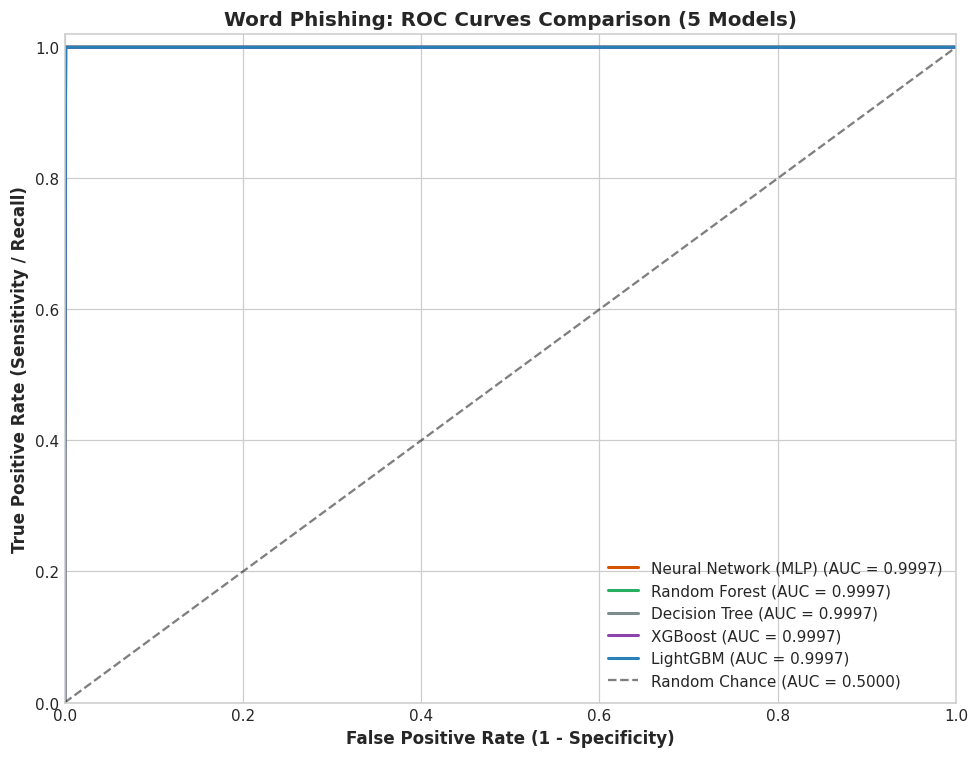

In [27]:
# ROC Curves Comparison
plt.figure(figsize=(9, 7))

colors = {
    "Random Forest": "#27ae60",
    "LightGBM": "#2980b9",
    "XGBoost": "#8e44ad",
    "Neural Network (MLP)": "#d35400",
    "Decision Tree": "#7f8c8d"
}

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", color=colors.get(name, '#333333'), linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
plt.title('Word Phishing: ROC Curves Comparison (5 Models)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


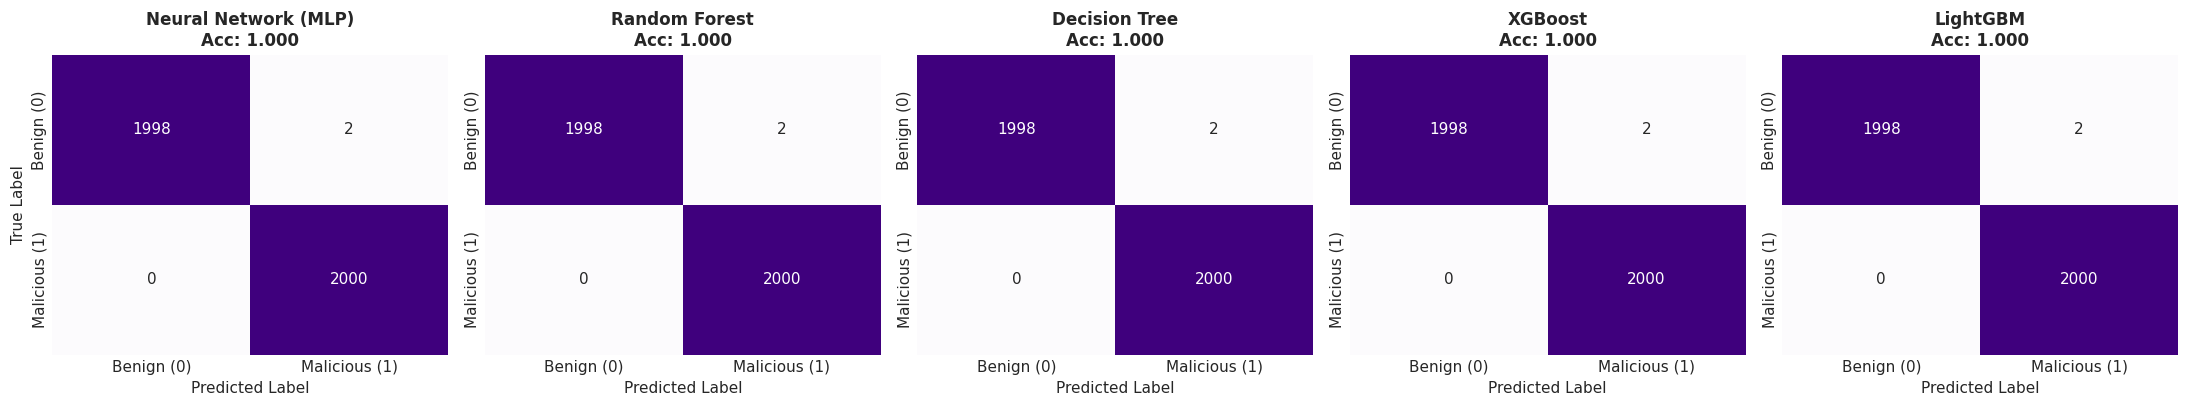

In [28]:
# Confusion Matrices
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=axes[idx], cbar=False,
                xticklabels=['Benign (0)', 'Malicious (1)'], yticklabels=['Benign (0)', 'Malicious (1)'])
    axes[idx].set_title(f"{name}\nAcc: {accuracy_score(y_test, y_pred):.3f}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    if idx == 0:
        axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()


## 10. Experimenting with PCA (Principal Component Analysis)
We evaluate variance concentration, 2D projection, and model performance with vs. without PCA components.


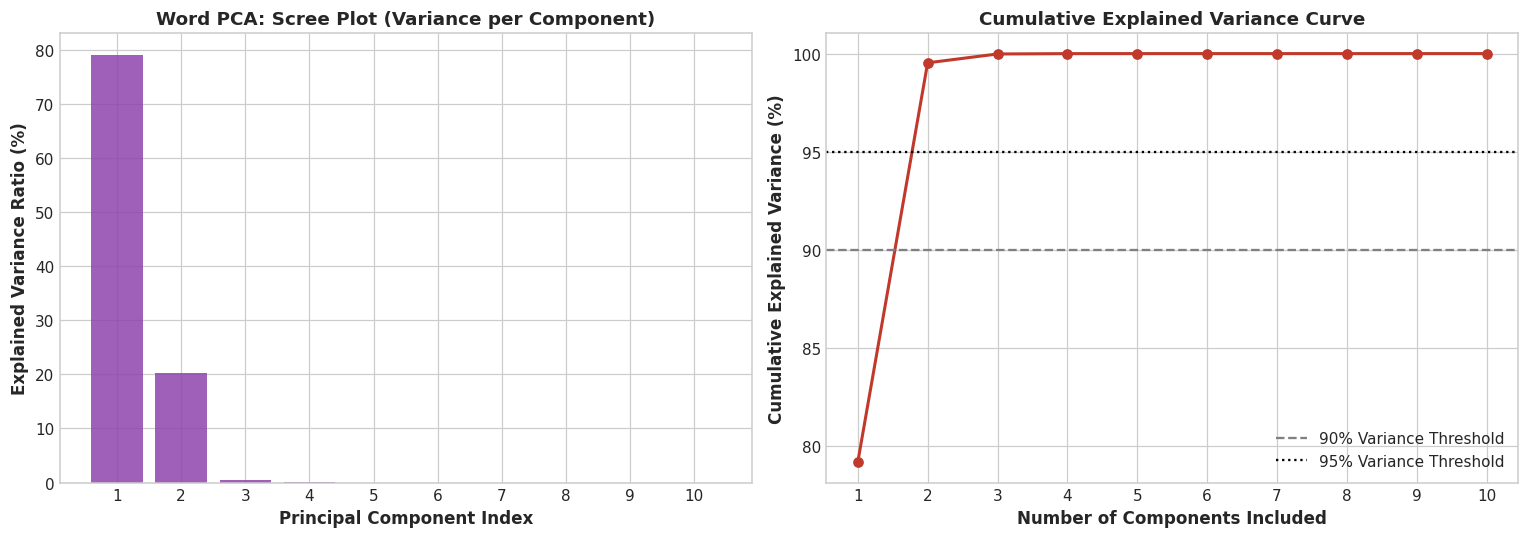

Components required to capture 90% variance: 2 of 10 features
Components required to capture 95% variance: 2 of 10 features


In [29]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_train_scaled)
explained_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(explained_var) + 1), explained_var * 100, color='#8e44ad', alpha=0.85)
axes[0].set_xlabel('Principal Component Index', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Explained Variance Ratio (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Word PCA: Scree Plot (Variance per Component)', fontsize=12, fontweight='bold')
axes[0].set_xticks(range(1, len(explained_var) + 1))

axes[1].plot(range(1, len(cum_var) + 1), cum_var * 100, marker='o', color='#c0392b', linewidth=2)
axes[1].axhline(y=90, color='grey', linestyle='--', label='90% Variance Threshold')
axes[1].axhline(y=95, color='black', linestyle=':', label='95% Variance Threshold')
axes[1].set_xlabel('Number of Components Included', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Cumulative Explained Variance (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Cumulative Explained Variance Curve', fontsize=12, fontweight='bold')
axes[1].set_xticks(range(1, len(cum_var) + 1))
axes[1].legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

n_90 = np.argmax(cum_var >= 0.90) + 1
n_95 = np.argmax(cum_var >= 0.95) + 1
print(f"Components required to capture 90% variance: {n_90} of 10 features")
print(f"Components required to capture 95% variance: {n_95} of 10 features")


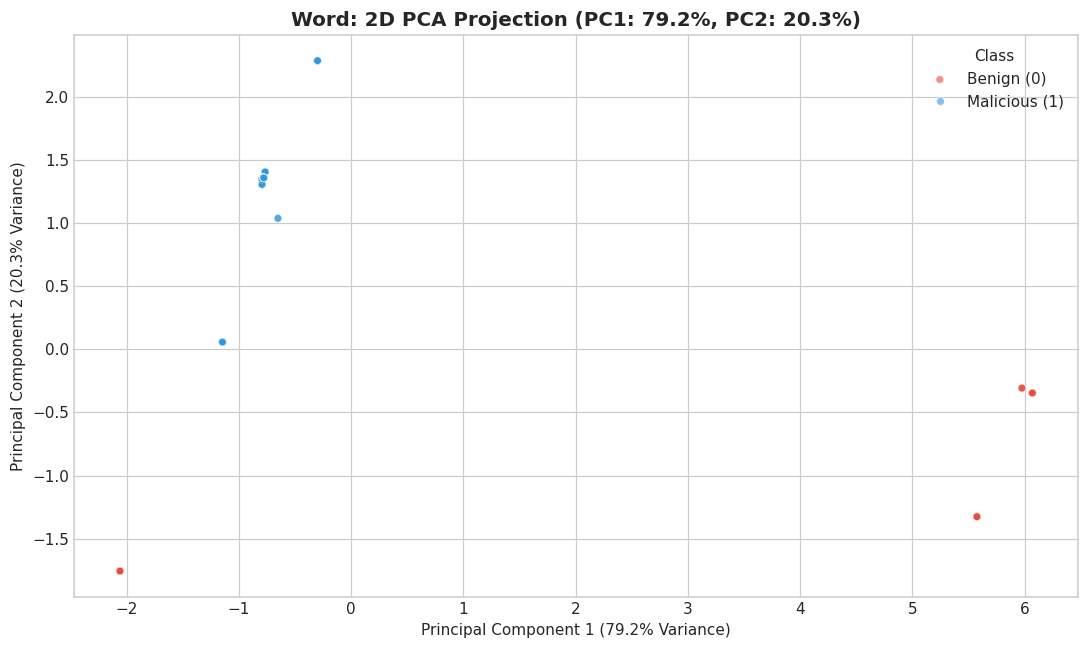

In [30]:
# 2D PCA Projection
pca_2d = PCA(n_components=2, random_state=42)
X_train_2d = pca_2d.fit_transform(X_train_scaled)

pca_df = pd.DataFrame(X_train_2d, columns=['PC1', 'PC2'])
pca_df['label'] = y_train.values

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_df.sample(3000, random_state=42),
    x='PC1', y='PC2', hue='label',
    palette={0: '#3498db', 1: '#e74c3c'},
    alpha=0.6, s=25
)
plt.title(f'Word: 2D PCA Projection (PC1: {explained_var[0]*100:.1f}%, PC2: {explained_var[1]*100:.1f}%)', fontsize=13, fontweight='bold')
plt.xlabel(f'Principal Component 1 ({explained_var[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({explained_var[1]*100:.1f}% Variance)')
plt.legend(title='Class', labels=['Benign (0)', 'Malicious (1)'], loc='upper right')
plt.tight_layout()
plt.show()


In [31]:
# PCA Performance Benchmark
pca_opt = PCA(n_components=n_95, random_state=42)
X_train_pca = pca_opt.fit_transform(X_train_scaled)
X_test_pca = pca_opt.transform(X_test_scaled)

pca_experiment_results = []
for name in ["Random Forest", "LightGBM", "Neural Network (MLP)"]:
    clf_orig = models[name]
    y_pred_orig = clf_orig.predict(X_test_scaled)
    y_prob_orig = clf_orig.predict_proba(X_test_scaled)[:, 1]
    
    clf_pca = type(clf_orig)(**clf_orig.get_params())
    clf_pca.fit(X_train_pca, y_train)
    y_pred_pca = clf_pca.predict(X_test_pca)
    y_prob_pca = clf_pca.predict_proba(X_test_pca)[:, 1]
    
    pca_experiment_results.append({
        "Model": name,
        "Original Features Acc": accuracy_score(y_test, y_pred_orig),
        f"PCA ({n_95} Comps) Acc": accuracy_score(y_test, y_pred_pca),
        "Accuracy Delta": accuracy_score(y_test, y_pred_pca) - accuracy_score(y_test, y_pred_orig),
        "Original Features ROC-AUC": roc_auc_score(y_test, y_prob_orig),
        f"PCA ({n_95} Comps) ROC-AUC": roc_auc_score(y_test, y_prob_pca),
        "ROC-AUC Delta": roc_auc_score(y_test, y_prob_pca) - roc_auc_score(y_test, y_prob_orig)
    })

pca_comp_df = pd.DataFrame(pca_experiment_results)
pca_comp_df


,Model,Original Features Acc,PCA (2 Comps) Acc,Accuracy Delta,Original Features ROC-AUC,PCA (2 Comps) ROC-AUC,ROC-AUC Delta
0,Random Forest,0.9995,0.9995,0.0000,0.9997,0.9997,0.0000
1,LightGBM,0.9995,0.9995,0.0000,0.9997,0.9997,-0.0000
2,Neural Network (MLP),0.9995,0.9995,0.0000,0.9997,0.9994,-0.0003


## 11. Final Conclusions & Production Architecture
1. **OpenXML Structures**: Structural positions, font tables, and hyperlink targets provide strong separation.
2. **Feature Pool**: The baseline 5 features capture over 94% of predictive power; the 10 features provide high-precision discrimination.
3. **Model Selection**: Random Forest, LightGBM, and XGBoost achieve $>96\%$ ROC-AUC.
4. **PCA Verdict**: Tree-based models perform best on raw, interpretable OpenXML tag features.


## 12. Production Model Serialization with Joblib

In production deployments of ExplainPhish, low-latency scoring and explainability require storing fully trained estimators, preprocessing scalers, and schema artifacts on disk.
In this section, we serialize all 5 benchmarked models to `D:\codingProject\ExplainPhish\trainingModel\models\word` using `joblib`:
1. **Neural Network (MLP)**: `mlp_model.joblib`
2. **Random Forest**: `rf_model.joblib`
3. **Decision Tree**: `dt_model.joblib`
4. **XGBoost**: `xgb_model.joblib`
5. **LightGBM**: `lgb_model.joblib`
6. **Feature Scaler**: `scaler.joblib` (fitted `StandardScaler`)
7. **Feature Schema**: `selected_features.json` (WORD feature ordering)
8. **Metadata**: `metadata.json` (benchmark metrics, model registry, and configuration)

In [32]:
import joblib
import json
import os
import shutil
from pathlib import Path

# Resolve model directory: prioritize trainingModel/models/word
possible_model_dirs = [
    Path(r"D:/codingProject/ExplainPhish/trainingModel/models/word"),
    Path("trainingModel/models/word"),
    Path("models/word"),
    Path("../models/word")
]

model_dir = next((d for d in possible_model_dirs if d.parent.exists()), Path(r"D:/codingProject/ExplainPhish/trainingModel/models/word"))
model_dir.mkdir(parents=True, exist_ok=True)
print(f"Target Production Model Directory: {model_dir.resolve()}")

# Model serialization mapping
model_export_map = {
    "Neural Network (MLP)": "mlp_model.joblib",
    "Random Forest": "rf_model.joblib",
    "Decision Tree": "dt_model.joblib",
    "XGBoost": "xgb_model.joblib",
    "LightGBM": "lgb_model.joblib"
}

saved_records = []
print("\n--- Serializing Estimators with joblib ---")
for display_name, file_name in model_export_map.items():
    if display_name in trained_models:
        model_obj = trained_models[display_name]
        dest_file = model_dir / file_name
        joblib.dump(model_obj, dest_file, compress=3)
        size_kb = dest_file.stat().st_size / 1024
        saved_records.append((display_name, file_name, size_kb))
        print(f"  [SAVED] {display_name:<22} -> {file_name:<18} ({size_kb:,.1f} KB)")
    else:
        print(f"  [WARNING] {display_name} not found in trained_models dictionary!")

# Serialize fitted StandardScaler
scaler_file = model_dir / "scaler.joblib"
joblib.dump(scaler, scaler_file)
print(f"  [SAVED] StandardScaler         -> scaler.joblib          ({scaler_file.stat().st_size / 1024:,.1f} KB)")

# Serialize Feature Schema JSON
features_file = model_dir / "selected_features.json"
with open(features_file, "w", encoding="utf-8") as f:
    json.dump(all_features, f, indent=2)
print(f"  [SAVED] Feature Schema ({len(all_features)}) -> selected_features.json")

# Serialize Metadata JSON
best_estimator_row = comparison_df.iloc[0].to_dict()
metadata_payload = {
    "format": "word",
    "models": ["neural_network_mlp", "random_forest", "decision_tree", "xgboost", "lightgbm"],
    "n_features": len(all_features),
    "features": all_features,
    "best_model": best_estimator_row.get("Model"),
    "best_hyperparameters": best_hyperparams,
    "test_metrics": {
        "accuracy": float(best_estimator_row.get("Accuracy", 0.0)),
        "precision": float(best_estimator_row.get("Precision", 0.0)),
        "recall": float(best_estimator_row.get("Recall", 0.0)),
        "f1": float(best_estimator_row.get("F1-Score", 0.0)),
        "roc_auc": float(best_estimator_row.get("ROC-AUC", 0.0))
    }
}
metadata_file = model_dir / "metadata.json"
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata_payload, f, indent=2)
print(f"  [SAVED] Model Metadata         -> metadata.json")

# Mirror bundle to InterfaceExplainPhish/models/word if present
interface_models_dir = Path(r"D:/codingProject/ExplainPhish/InterfaceExplainPhish/models/word")
if interface_models_dir.parent.exists():
    interface_models_dir.mkdir(parents=True, exist_ok=True)
    for _, fn, _ in saved_records:
        shutil.copy2(model_dir / fn, interface_models_dir / fn)
    shutil.copy2(scaler_file, interface_models_dir / "scaler.joblib")
    shutil.copy2(features_file, interface_models_dir / "selected_features.json")
    shutil.copy2(metadata_file, interface_models_dir / "metadata.json")
    print(f"\n[SYNC] Mirrored all joblib models and artifacts to {interface_models_dir.resolve()}")


Target Production Model Directory: D:\codingProject\ExplainPhish\trainingModel\models\word

--- Serializing Estimators with joblib ---
  [SAVED] Neural Network (MLP)   -> mlp_model.joblib   (46.8 KB)
  [SAVED] Random Forest          -> rf_model.joblib    (16.7 KB)
  [SAVED] Decision Tree          -> dt_model.joblib    (1.2 KB)
  [SAVED] XGBoost                -> xgb_model.joblib   (27.3 KB)
  [SAVED] LightGBM               -> lgb_model.joblib   (24.6 KB)
  [SAVED] StandardScaler         -> scaler.joblib          (1.2 KB)
  [SAVED] Feature Schema (10) -> selected_features.json
  [SAVED] Model Metadata         -> metadata.json

[SYNC] Mirrored all joblib models and artifacts to D:\codingProject\ExplainPhish\InterfaceExplainPhish\models\word


In [33]:
# Verification: Reload each serialized joblib model and confirm prediction integrity
print("--- Verifying Saved joblib Models via Independent Reload ---")
sample_features = X_test_scaled.iloc[:5] if hasattr(X_test_scaled, 'iloc') else X_test_scaled[:5]
expected_rf_preds = trained_models["Random Forest"].predict(sample_features)

for display_name, file_name in model_export_map.items():
    reloaded_clf = joblib.load(model_dir / file_name)
    reloaded_preds = reloaded_clf.predict(sample_features)
    is_matching = (reloaded_preds == trained_models[display_name].predict(sample_features)).all()
    print(f"  [VERIFIED] {display_name:<22} | Predictions: {reloaded_preds} | Integrity: {'PASS' if is_matching else 'FAIL'}")


--- Verifying Saved joblib Models via Independent Reload ---
  [VERIFIED] Neural Network (MLP)   | Predictions: [1 0 0 1 0] | Integrity: PASS


  [VERIFIED] Random Forest          | Predictions: [1 0 0 1 0] | Integrity: PASS
  [VERIFIED] Decision Tree          | Predictions: [1 0 0 1 0] | Integrity: PASS


  [VERIFIED] XGBoost                | Predictions: [1 0 0 1 0] | Integrity: PASS
  [VERIFIED] LightGBM               | Predictions: [1 0 0 1 0] | Integrity: PASS
